# E113 · Is the 100-year flood still a 100-year flood? Two centuries of Susquehanna peaks, the floods nobody gauged, and a river that got calmer

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: USGS National Water Information System annual peak-flow files (US federal work, public domain), retrieved 2026-11-06, for 12 gauges on the Susquehanna, Juniata, West Branch, Potomac and Schuylkill: 1,383 rows in the file, of which 1,351 gauged and 20 historic annual peaks are used; Harrisburg has six historic floods from 1786-1889 and a gapless gauged record for water years 1891-2024. Drainage areas from the NWIS site service. Built by `tools/build_e113_peaks.py`. Regional skew prior from Veilleux & Wagner (2021), USGS SIR 2021-5015 (public domain) |
| **You will learn** | The **log-Pearson III** distribution of Bulletin 17C written in PyTensor · a library gradient that is wrong where the data live (PyTensor's incomplete-gamma derivative in the shape) and its replacement by **quadrature**, with unit tests · a support wall that *rewards* points outside it · **historical floods as censored data**: "at least this big" and "nothing above the mark for a century" · a **latent perception threshold** summed out exactly, with chance records · a **regional skew prior** and a hierarchical skew pooled over 12 gauges · a centred location that strands chains at a moving support · stationary, step and trend models compared by **PSIS-LOO** and **stacking**, leaving out whole water years because twelve gauges share their storms · for the public: **chance-of bars** over a 30-year mortgage with gradient whiskers, grey reference bars, a "what would change our mind" strip and a flood-marks **HOP GIF** |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: one BLAS pool per chain would fight

import logging
import sys
import textwrap
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor
import pytensor.tensor as pt
import xarray as xr
from IPython.display import Markdown, display
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from scipy import special, stats

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 113
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
warnings.filterwarnings("ignore", message="There are no gridspecs with layoutgrids")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()
TIMES = {}
INK, MUTED, LIGHT, HI, LO = pub.INK, pub.MUTED, pub.LIGHT, pub.HI, pub.LO


def wrap(text, width=90):
    return "\n".join(textwrap.fill(t, width) for t in text.split("\n"))


def pct(p):
    """Whole percent, with '<1%' below 1% so the number agrees with 'exceptionally unlikely'."""
    return "<1%" if p < 0.01 else pub.fmt_pct(p)


print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, nutpie {nutpie.__version__}")

PyMC 6.3.2, ArviZ 1.3.0, nutpie 0.16.11


## In plain words

**The question.** My Harrisburg house is just outside the "100-year floodplain". What is the
chance the river reaches it during a 30-year mortgage, and do the floods of 1786-1889 change that?

**What we did.** We fitted the standard flood curve to 134 years of gauged peaks, six older
floods and the quiet years between, sharing its shape with eleven neighbouring gauges.

**What we found.** We compute a "textbook" 100-year flow the standard way, from the gauged years
(the official map may differ). At face value it is beaten in 26 of 100 thirty-year
stretches. Old floods that never came close say it is rarer: with the neighbours, about 14 in
100. Yearly peaks have run about a tenth lower than before mid-century; if that lasts, about 8.
Weighing that drop against no change: about 11. For a house 2 ft above the line: about 4.

**How sure are we.** It is *unlikely* (11%) that the river beats the textbook 100-year flow at least once in 2025-2054. We have *low confidence* in that figure: its range runs from *very unlikely* (3%) to *unlikely* (22%), and it weighs a drop of unknown cause (at Harrisburg alone 95% likely if steady, 85% if a step) against no change (about 14%).

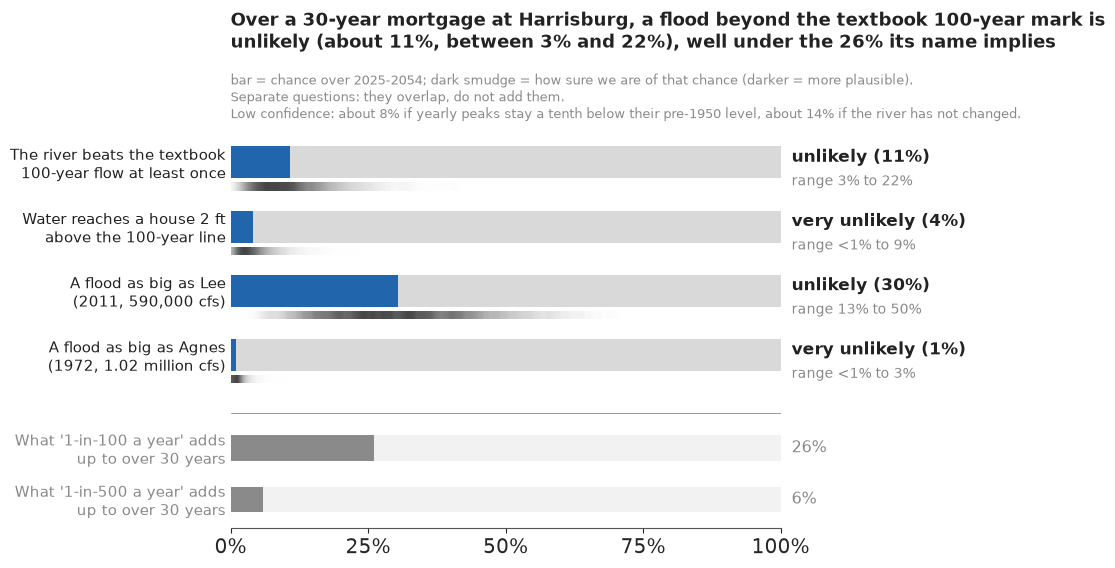

In [2]:
HOW_SURE = display(Markdown("**How sure are we.** *Filled in from the fits in part G.*"),
                   display_id=True)
HEADLINE = display(Markdown("*The headline figure is drawn in part G from the fits below and "
                            "appears here once the notebook has run.*"), display_id=True)

## The setting

Harrisburg has flooded for as long as there has been a Harrisburg. The "Pumpkin Flood" of October
1786 carried pumpkins from the fields down the river; the ice-jam flood of March 1865 and the
flood of June 1889 (the same storm that broke the dam above Johnstown) left marks that stood for
decades. The gauge came in 1891. Since then the river has beaten those marks twice: in March 1936,
and in June 1972, when Tropical Storm Agnes put a million cubic feet per second past the city, the
largest flow in its record. Tropical Storm Lee (September 2011) is fourth in the gauged record,
behind 1972, 1936 and 1894.

The public meets this history through one phrase, the **100-year flood**: the flow with a 1%
chance of being beaten in any one year. It is the line on the flood map that decides who must buy
flood insurance, and it is misunderstood in two ways. People hear "once a century", when 1% a year
adds up to about a 26% chance over a 30-year mortgage; and they hear a fixed fact about the river,
when it is an estimate from about a century of yearly peaks, a sample in which the floods that
matter most are the rarest.

The US method is Bulletin 17C (England et al. 2019, USGS Techniques and Methods 4-B5): fit a
**log-Pearson III** distribution to the logarithms of the annual peaks, borrow its skew from a
regional study, and use historical floods where they are known. The idea that "at least this
big" and "nothing bigger for a century" are data, not anecdotes, is Stedinger & Cohn's (1986,
*Water Resources Research*); Cohn, Lane & Baier (1997) turned it into the expected moments
algorithm that 17C uses. Kuczera (1999) and Reis & Stedinger (2005) gave the same likelihood a
Bayesian treatment, in which the regional skew becomes what it always was, a prior. For eastern
New York and Pennsylvania that prior is Veilleux & Wagner's (2021, USGS SIR 2021-5015) regional
skew of 0.32 with mean squared error 0.11, from 183 gauges unaffected by extensive regulation.
Coles (2001) is the general reference for extremes; E37 fitted block maxima with a GEV.

The title asks a second question. Bulletin 17C assumes the river does not change, and Milly et
al. (2008, *Science*) argued that "stationarity is dead". Heavier rain is the usual worry, but the
Susquehanna has also gained flood-control dams, regrown forests and fewer ice jams. Here the data
go against the expected headline: the peaks have probably fallen.

The plan builds the answer one piece of information at a time and turns it into the chance of
four named floods over 2025-2054. It is a lesson in modelling, not an engineering flood study:
for a real property, the FEMA flood maps and a local engineer are the place to start.

| part | question | tool |
|---|---|---|
| A | What do two centuries at Harrisburg look like? | gauged and historic peaks, completeness |
| B | What does "100-year" mean? | the 26% arithmetic, the textbook flow, a stage-flow rating |
| C | What does one gauge say alone? | log-Pearson III in PyTensor, two failures, prior check |
| D | What do the floods of 1786-1889 add? | censored terms, a latent perception threshold |
| E | What do eleven neighbours add? | area scaling, a hierarchical skew |
| F | Is the river changing? | trend and step models, a third failure, year-blocked LOO, stacking |
| G | How do we explain it to everyone? | chance-of bars, return levels, a strip, a GIF |

## A · Two centuries at Harrisburg

The data are USGS annual peak-flow files for 12 gauges, joined into one table by
`tools/build_e113_peaks.py`. Each row is the largest flow of one **water year** (October to
September, so the Pumpkin Flood of 5 October 1786 belongs to water year 1787). A code 7 marks a
historic peak, measured from a flood mark rather than by the gauge; codes 5 and 6 mark peaks
affected by regulation. Water year 2026 at Hancock is partial and provisional, so we stop at 2025.

In [3]:
data.describe("e113_peaks")
PEAKS = data.load("e113_peaks")
LAST_WY = 2025
PEAKS = PEAKS[PEAKS["water_year"] <= LAST_WY].copy()
HBG = "01570500"
SHORT = {"01570500": "Harrisburg", "01536500": "Wilkes-Barre", "01531500": "Towanda",
         "01540500": "Danville", "01553500": "Lewisburg (W. Br.)", "01567000": "Newport (Juniata)",
         "01576000": "Marietta", "01503000": "Conklin NY", "01638500": "Point of Rocks",
         "01613000": "Hancock", "01646500": "Little Falls", "01474500": "Philadelphia (Schuylkill)"}
ORDER = list(SHORT)
summ = (PEAKS.groupby("site_no")
        .agg(area=("drain_sqmi", "first"), peaks=("peak_cfs", "count"), first=("water_year", "min"),
             historic=("historic", "sum"), regulated=("regulated", "sum"))
        .reindex(ORDER).rename(index=SHORT))
print(summ.to_string())
print(f"{int(PEAKS['peak_cfs'].notna().sum()):,} peaks with a flow")

e113_peaks: One row per recorded annual peak (1,383 rows): site_no, station, drain_sqmi, lat, lon, water_year (October-September), peak_date, peak_cfs (cubic feet per second), gage_ht_ft, peak_cd (NWIS codes, comma-separated), historic (code 7: a historic peak outside the systematic record), regulated (code 5 or 6), estimate (code 2), year_last_pk ('highest since'). Harrisburg (01570500) has six historic peaks 1786-1889 and a gapless systematic record for water years 1891-2024. Water year 2026 at Hancock is a partial, provisional year. Danville and Lewisburg have long gaps before their continuous records.
  source: USGS National Water Information System annual peak-flow files (US federal work, public domain), retrieved 2026-11-06, for 12 gauges on the Susquehanna, Juniata, West Branch, Potomac and Schuylkill, with drainage areas and coordinates from the NWIS site service. DERIVED by tools/build_e113_peaks.py; the url is the Harrisburg file, not this table - keep the cached file in data

In [4]:
hb = PEAKS[PEAKS["site_no"] == HBG]
HB_SYS = hb[(hb["historic"] == 0) & hb["peak_cfs"].notna()]
HB_HIST = hb[hb["historic"] == 1]
print(HB_HIST[["water_year", "peak_date", "peak_cfs", "gage_ht_ft"]].to_string(index=False))
print(f"gauged: water years {HB_SYS.water_year.min()}-{HB_SYS.water_year.max()}, "
      f"n = {len(HB_SYS)}, "
      f"gaps: {HB_SYS.water_year.max() - HB_SYS.water_year.min() + 1 - len(HB_SYS)}; "
      f"regulated codes: {int(hb['regulated'].sum())}")
big = HB_SYS.nlargest(5, "peak_cfs")[["water_year", "peak_cfs", "gage_ht_ft"]]
print("largest gauged peaks:\n" + big.to_string(index=False))

 water_year  peak_date  peak_cfs  gage_ht_ft
       1787 1786-10-05  482000.0       22.00
       1846 1846-03-15  482000.0       22.00
       1865 1865-03-18  573000.0       24.60
       1868 1868-03-19  417000.0       20.00
       1886 1886-01-06  385000.0       19.02
       1889 1889-06-02  654000.0       26.80
gauged: water years 1891-2024, n = 134, gaps: 0; regulated codes: 0
largest gauged peaks:
 water_year  peak_cfs  gage_ht_ft
       1972 1020000.0       32.57
       1936  740000.0       29.23
       1894  613000.0       25.70
       2011  590000.0       25.17
       1996  568000.0       24.66


Harrisburg's file holds six historic floods, from 482,000 cfs in 1786 to 654,000 in 1889, and a
gauged record with no missing year. Two gauged floods are larger than any historic one: 1936
(740,000) and Agnes in 1972 (1,020,000). Harrisburg carries no regulation code, although the
reservoirs built upstream after 1936 do hold back some of its floods; five other gauges carry the
codes for decades.

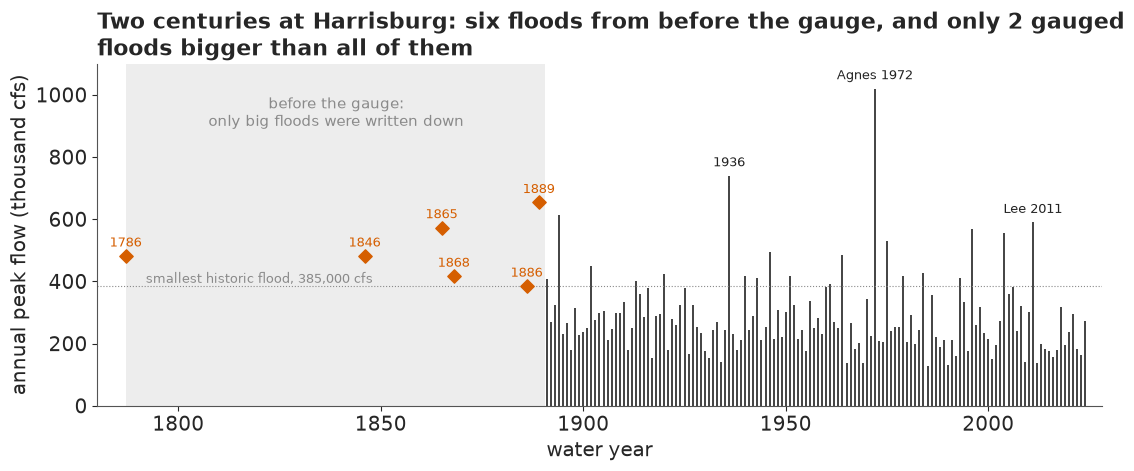

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.axvspan(1787, 1890.5, color=LIGHT, alpha=0.45, lw=0)
ax.vlines(HB_SYS.water_year, 0, HB_SYS.peak_cfs / 1e3, color=INK, lw=1.2)
ax.scatter(HB_HIST.water_year, HB_HIST.peak_cfs / 1e3, marker="D", s=46, color=LO, zorder=4)
for _, r in HB_HIST.iterrows():
    yr_lab = r.water_year - 1 if r.water_year == 1787 else r.water_year  # Pumpkin Flood, 1786
    ax.text(r.water_year, r.peak_cfs / 1e3 + 30, f"{yr_lab}", ha="center", fontsize=9.5, color=LO)
for wy, lab in ((1936, "1936"), (1972, "Agnes 1972"), (2011, "Lee 2011")):
    v = float(HB_SYS.loc[HB_SYS.water_year == wy, "peak_cfs"].iloc[0]) / 1e3
    ax.text(wy, v + 30, lab, ha="center", fontsize=9.5, color=INK)
ax.axhline(385, color=MUTED, lw=0.8, ls=":")
ax.text(1792, 395, "smallest historic flood, 385,000 cfs", fontsize=9.5, color=MUTED)
ax.text(1839, 900, "before the gauge:\nonly big floods were written down", ha="center",
        fontsize=10.5, color=MUTED)
ax.set_xlim(1780, 2028)
ax.set_ylim(0, 1100)
ax.set_xlabel("water year")
ax.set_ylabel("annual peak flow (thousand cfs)")
n_above = int((HB_SYS.peak_cfs > HB_HIST.peak_cfs.max()).sum())
ax.set_title(wrap(f"Two centuries at Harrisburg: six floods from before the gauge, and only "
                  f"{n_above} gauged floods bigger than all of them", 80), loc="left");

Between 1787 and 1890 we know of six floods, and we know something just as useful about the
other 98 years: nobody recorded anything to rival them. The convention in 17C is to take the
smallest recorded historic peak as the **perception threshold**, the flow above which a flood
would have been noticed and written down, so that every unrecorded year counts as "below 385,000".
The gauged years let us test that convention before we use it.

In [6]:
n_sys, T_HIST = len(HB_SYS), 1891 - 1787
rows = []
for X in (385e3, 417e3, 482e3, 573e3):
    k_sys = int((HB_SYS.peak_cfs >= X).sum())
    rows.append(dict(threshold=f"{X:,.0f}", gauged_above=k_sys,
                     expected_in_104_years=round(k_sys * T_HIST / n_sys, 1),
                     recorded_above=int((HB_HIST.peak_cfs >= X).sum())))
print(pd.DataFrame(rows).to_string(index=False))

threshold  gauged_above  expected_in_104_years  recorded_above
  385,000            20                   15.5               6
  417,000            13                   10.1               5
  482,000             9                    7.0               4
  573,000             4                    3.1               2


If floods were as frequent before 1891 as after, 104 years would hold about 15 floods above
385,000 cfs; the record names 6. Above 482,000 the gap is 7 against 4, and above 573,000 about 3
against 2. Either the nineteenth century was calmer, or the smaller of its floods went unrecorded,
or both; the record looks complete only near its top. So the threshold is uncertain, and part D
will treat it as a latent variable over the recorded values instead of fixing it at the smallest.

## B · What "100-year" means

### The arithmetic of a mortgage

A flow with a 1% chance of being beaten in any year is beaten at least once in 30 independent
years with probability

$$ P_{30} = 1 - (1 - 0.01)^{30} \approx 0.26. $$

More generally, if $F(x)$ is the probability that a year's peak stays below $x$, the chance of at
least one peak above $x$ in the years $t = 1, \dots, 30$ is $1 - \prod_t F_t(x)$, which allows the
river to change from year to year. Every public number in this notebook is of that form.

In [7]:
for T_ret in (10, 50, 100, 500):
    print(f"{T_ret:>4}-year flow: {1 - (1 - 1 / T_ret) ** 30:.1%} chance of at least one in 30 "
          "years")

  10-year flow: 95.8% chance of at least one in 30 years
  50-year flow: 45.5% chance of at least one in 30 years
 100-year flow: 26.0% chance of at least one in 30 years
 500-year flow: 5.8% chance of at least one in 30 years


We keep two of these as reference bars for the public figures: 26% for the 100-year flow, the
figure FEMA's FloodSmart pages give for a 30-year mortgage in a high-risk zone, and about 6% for
the 500-year flow, the same arithmetic one zone further out.

### The textbook 100-year flow

We found no official 1% flow for Harrisburg that we could check, so we compute a **textbook**
value the way Bulletin 17B did it by hand, from the gauged years alone (17C would also use the
historic floods, which is what part D does): the mean $m$, sd $s$ and skew $G$ of the 134 gauged
log10 peaks, the station skew weighted with the regional skew by their mean squared errors,

$$ G_w = \frac{\text{MSE}_R\, G + \text{MSE}_G\, G_R}{\text{MSE}_R + \text{MSE}_G}, \qquad
   Q_{100} = 10^{\,m + s\, K(G_w, 0.99)}, $$

with $K$ the Pearson III frequency factor and $\text{MSE}_G$ from the 17B formula in the record
length. It is a fixed number, the kind a flood map is drawn from, and our questions are about it.

In [8]:
q_hb = np.log10(HB_SYS.peak_cfs.values)
m_, s_ = q_hb.mean(), q_hb.std(ddof=1)
G_st = stats.skew(q_hb, bias=False)
REG_SKEW, REG_SKEW_SD = 0.32, np.sqrt(0.11)  # Veilleux & Wagner (2021), SIR 2021-5015
A_ = -0.33 + 0.08 * abs(G_st) if abs(G_st) <= 0.9 else -0.52 + 0.30 * abs(G_st)
B_ = 0.94 - 0.26 * abs(G_st) if abs(G_st) <= 1.5 else 0.55
MSE_G = 10 ** (A_ - B_ * np.log10(n_sys / 10))
G_W = (REG_SKEW_SD**2 * G_st + MSE_G * REG_SKEW) / (REG_SKEW_SD**2 + MSE_G)
Q100_TXT = 10 ** stats.pearson3.ppf(0.99, G_W, loc=m_, scale=s_)
print(f"log10 peaks: mean {m_:.4f}, sd {s_:.4f}, station skew {G_st:.3f} (MSE {MSE_G:.3f}); "
      f"weighted skew {G_W:.3f}")
print(f"textbook 100-year flow: {Q100_TXT:,.0f} cfs "
      f"(station skew alone: {10 ** stats.pearson3.ppf(0.99, G_st, loc=m_, scale=s_):,.0f})")

log10 peaks: mean 5.4195, sd 0.1624, station skew 0.590 (MSE 0.068); weighted skew 0.487
textbook 100-year flow: 714,792 cfs (station skew alone: 734,172)


The textbook 100-year flow at Harrisburg is about 715,000 cfs. The station's own skew, 0.59, is
well above the regional 0.32; the weighting pulls it to 0.49, and the flow down by 3%.

### From flow to height

A house is flooded by water height, not flow. The peak file gives the gauge height of most peaks,
so the modern pairs (water years 1970 on, stages of 15 ft and more) give a rating curve, a
straight line in log flow against stage. With it we name one more event: water 2 ft above the
textbook 100-year line, a house that sits a little higher than the line.

In [9]:
rr = HB_SYS[(HB_SYS.water_year >= 1970) & (HB_SYS.gage_ht_ft >= 15)]
RA, RB = np.polyfit(rr.gage_ht_ft, np.log10(rr.peak_cfs), 1)
res_r = np.log10(rr.peak_cfs) - (RA * rr.gage_ht_ft + RB)


def stage(Q):
    return (np.log10(Q) - RB) / RA


def flow(h):
    return 10 ** (RA * h + RB)


H100 = stage(Q100_TXT)
Q_2FT = flow(H100 + 2)
print(f"rating from {len(rr)} peaks: log10 Q = {RA:.4f} h + {RB:.3f}, residual sd "
      f"{(10 ** res_r.std() - 1):.0%} in flow")
rr_x = rr[rr.water_year != 1972]  # refit without Agnes: an out-of-sample check
RA_x, RB_x = np.polyfit(rr_x.gage_ht_ft, np.log10(rr_x.peak_cfs), 1)
h_agnes_x = (np.log10(1.02e6) - RB_x) / RA_x
print(f"100-year line {H100:.1f} ft; 2 ft higher = {Q_2FT:,.0f} cfs; Agnes on the line "
      f"{stage(1.02e6):.1f} ft, on a line fitted without Agnes {h_agnes_x:.1f} ft (recorded 32.57)")

rating from 22 peaks: log10 Q = 0.0338 h + 4.920, residual sd 3% in flow
100-year line 27.7 ft; 2 ft higher = 835,078 cfs; Agnes on the line 32.2 ft, on a line fitted without Agnes 31.9 ft (recorded 32.57)


Each foot near flood stage adds about 8% to the flow. The textbook line sits at 27.7 ft on the
gauge, and 2 ft above it is about 835,000 cfs. Refitted without Agnes, the rating still puts Agnes
within about a foot, the limit to which we trust it; we do not carry that error into the 2 ft
event's probability.

## C · One gauge, the gauged years

### The log-Pearson III distribution

With $q = \log_{10}$ (peak flow), the Pearson III distribution with mean $\mu$, sd $\sigma$ and
skew $\gamma > 0$ is a shifted gamma distribution with shape $a = 4/\gamma^2$. In standard units
$z = (q - \mu)/\sigma$, write $u = z\gamma/2$; then $y = a(1 + u)$ is a Gamma($a$, 1) variate
and

$$ \log p(z) = (a - 1)\log(1 + u) - a u + \Big[(a - \tfrac12)\log a - a - \log\Gamma(a)\Big],
   \qquad u > -1, $$

where the bracket already includes the Jacobian $\sqrt{a}$ of $y = a + z\sqrt{a}$, and is
written with a Stirling series for large $a$, so
the density stays finite as $\gamma \to 0$, where it becomes the normal. For $\gamma < 0$ the
same formula holds with the support bounded above. Either way the support has a wall at
$z = -2/\gamma$, and the wall moves with every parameter.

The density is all the gauged years need. The historical floods of part D also need the tail
probability $S(x) = P(q > x)$, which for a gamma variate is the regularised incomplete gamma
function, `pt.gammaincc(a, y)` in PyTensor, and its gradient with respect to the shape $a$.

### Failure 1: a gradient that is wrong where the data live

A skew near 0.3 means a shape near 44. The cell below compares PyTensor's derivative of
`gammaincc` and `gammainc` in $a$ with a finite difference of SciPy's values, at a point $1.5$ sd
either side of the gamma's mean.

In [10]:
a_s, y_s = pt.dscalars("a", "y")
d_inc = pytensor.function([a_s, y_s], [pt.grad(pt.gammainc(a_s, y_s), a_s),
                                       pt.grad(pt.gammaincc(a_s, y_s), a_s)])
rows = []
for A in (11.0, 44.0, 100.0, 400.0, 1600.0):
    for zz in (-1.5, 1.5):
        Y = A + zz * np.sqrt(A)
        h = 1e-5 * A
        fd = (special.gammainc(A + h, Y) - special.gammainc(A - h, Y)) / (2 * h)
        dP, dQ = d_inc(A, Y)
        rows.append(dict(shape=A, skew=round(2 / np.sqrt(A), 3), y=f"mean {zz:+.1f} sd",
                         dP_pytensor=f"{float(dP):+.3e}", dP_true=f"{fd:+.3e}",
                         dQ_pytensor=f"{float(dQ):+.3e}", dQ_true=f"{-fd:+.3e}"))
print(pd.DataFrame(rows).to_string(index=False))

 shape  skew            y dP_pytensor    dP_true dQ_pytensor    dQ_true
  11.0 0.603 mean -1.5 sd  -3.108e-02 -3.108e-02  +3.111e-02 +3.108e-02
  11.0 0.603 mean +1.5 sd  -4.187e-02 -4.187e-02  +4.187e-02 +4.187e-02
  44.0 0.302 mean -1.5 sd  -1.807e-02 -1.807e-02  +2.265e+10 +1.807e-02
  44.0 0.302 mean +1.5 sd  -2.039e-02 -2.039e-02  +1.994e-02 +2.039e-02
 100.0 0.200 mean -1.5 sd  -1.237e-02 -1.237e-02  -3.158e+54 +1.237e-02
 100.0 0.200 mean +1.5 sd  -1.336e-02 -1.336e-02  +1.241e-02 +1.336e-02
 400.0 0.100 mean -1.5 sd  -6.343e-03 -6.343e-03        +nan +6.343e-03
 400.0 0.100 mean +1.5 sd  -6.588e-03 -6.588e-03        +nan +6.588e-03
1600.0 0.050 mean -1.5 sd        +nan -3.206e-03        +nan +3.206e-03
1600.0 0.050 mean +1.5 sd        +nan -3.267e-03        +nan +3.267e-03


At shape 11 (skew 0.6) the two agree. At shape 44, the skew these rivers have, the derivative of
`gammaincc` below the mean is off by orders of magnitude, and from shape 400 (skew 0.1) one or
both come back as NaN or absurd. NUTS would follow those gradients without complaint. The
lesson is the one E32 learned for `betainc`: test a library special function's parameter
gradient at the values your posterior will visit before sampling with it.

The fix avoids the incomplete gamma function altogether. The tail probability is an integral of
the stable density, and over a fixed set of Gauss-Legendre nodes the integral is a weighted sum
whose gradient is exact. For $\gamma > 0$ we map $z \in (z_0, \infty)$ to $w \in (0, 1)$ by $z =
z_0 + w/(1 - w)$; for $\gamma < 0$ the tail ends at the wall $-2/\gamma$ (at most 12 sd away):

$$ \log S(z_0) = \log \sum_{j=1}^{48} \omega_j\, \frac{p\big(z_0 + \tfrac{w_j}{1 - w_j}\big)}
   {(1 - w_j)^2}, $$

evaluated with `logsumexp`, and $\log F = \log(1 - S)$ with `log1mexp`.

In [11]:
NODES = 48
_gx, _gw = np.polynomial.legendre.leggauss(NODES)
GL_X, GL_W = 0.5 * (_gx + 1.0), 0.5 * _gw  # nodes and weights on (0, 1)


def p3_std_logpdf(z, g):
    """log density of the standardised Pearson III (mean 0, sd 1, skew g); clamped at the wall."""
    a = 4.0 / g**2
    u = z * g / 2.0  # the gamma variate is a (1 + u)
    a_lo, a_hi = pt.minimum(a, 1e3), pt.maximum(a, 1e3)  # exact below a = 1000, Stirling above
    stir = pt.switch(a < 1e3, (a_lo - 0.5) * pt.log(a_lo) - a_lo - pt.gammaln(a_lo),
                     -0.5 * np.log(2 * np.pi) - 1.0 / (12.0 * a_hi) + 1.0 / (360.0 * a_hi**3))
    return (a - 1.0) * pt.log1p(pt.maximum(u, -1.0 + 1e-15)) - a * u + stir


def p3_logp(q, mu, sigma, g):
    """log density at q, and -inf outside the support."""
    z = (q - mu) / sigma
    return pt.switch(z * g / 2.0 > -1.0, p3_std_logpdf(z, g) - pt.log(sigma), -np.inf)


def p3_logsf(q, mu, sigma, g):
    """log P(Q > q) by 48-node Gauss-Legendre quadrature of the density (no gammainc gradient)."""
    z0 = pt.as_tensor_variable((q - mu) / sigma)[..., None]
    g_ = pt.as_tensor_variable(g)[..., None]
    zu = z0 + GL_X / (1.0 - GL_X)  # g > 0: unbounded upper tail
    lu = p3_std_logpdf(zu, pt.maximum(g_, 1e-4)) + np.log(GL_W / (1.0 - GL_X) ** 2)
    L = pt.clip(-2.0 / pt.minimum(g_, -1e-4) - z0, 1e-300, 12.0)  # g < 0: ends at the wall
    lb = p3_std_logpdf(z0 + L * GL_X, pt.minimum(g_, -1e-4)) + pt.log(GL_W * L)
    return pt.logsumexp(pt.switch(g_ > 0, lu, lb), axis=-1)


def p3_logcdf(q, mu, sigma, g):
    return pt.log1mexp(pt.minimum(p3_logsf(q, mu, sigma, g), -1e-12))

Before any sampling, the new functions are checked against `scipy.stats.pearson3` at 2,000
random points (skew between -1.5 and 1.5, up to 4.5 sd into the upper tail), and their gradients
against finite differences of SciPy's at 150 more.

In [12]:
qv, mv, sv, gv = pt.dvectors("q", "mu", "s", "g")
f_p3 = pytensor.function([qv, mv, sv, gv], [p3_logp(qv, mv, sv, gv), p3_logsf(qv, mv, sv, gv),
                                           p3_logcdf(qv, mv, sv, gv)])
tr_ = np.random.default_rng(2)
n_t = 2000
G_t, M_t, S_t = tr_.uniform(-1.5, 1.5, n_t), tr_.uniform(4.5, 5.6, n_t), tr_.uniform(0.1, 0.3, n_t)
Q_t = M_t + S_t * tr_.uniform(-1.0, 4.5, n_t)
ref = stats.pearson3(G_t, loc=M_t, scale=S_t)
lp_t, lsf_t, lcdf_t = f_p3(Q_t, M_t, S_t, G_t)
ok_t = np.isfinite(ref.logsf(Q_t)) & np.isfinite(ref.logpdf(Q_t))
print(f"max abs error over {ok_t.sum()} points: "
      f"logpdf {np.abs(lp_t - ref.logpdf(Q_t))[ok_t].max():.1e}, "
      f"logsf {np.abs(lsf_t - ref.logsf(Q_t))[ok_t].max():.1e}, "
      f"logcdf {np.abs(lcdf_t - ref.logcdf(Q_t))[ok_t].max():.1e}")
for gg in (1e-3, -1e-3, 0.02):
    e = f_p3(np.array([5.3, 5.6]), np.full(2, 5.0), np.full(2, 0.2), np.full(2, gg))[1] - \
        stats.pearson3(gg, loc=5.0, scale=0.2).logsf([5.3, 5.6])
    print(f"  skew {gg:+.3f}: logsf error {np.abs(e).max():.1e}")
qs_, ms_, ss_, gs_ = pt.dscalars("q", "m", "s", "g")
f_grad = pytensor.function([qs_, ms_, ss_, gs_],
                           pt.grad(p3_logcdf(qs_, ms_, ss_, gs_), [qs_, ms_, ss_, gs_]))
worst = 0.0
for _ in range(150):
    gg, s0, z0 = tr_.uniform(-1.2, 1.2), tr_.uniform(0.12, 0.25), tr_.uniform(0.5, 3.0)
    if gg < 0 and z0 > -2 / gg - 0.3:
        continue
    args = [5.0 + s0 * z0, 5.0, s0, gg]
    out = f_grad(*args)
    for j in range(4):
        up, dn = list(args), list(args)
        up[j] += 1e-6
        dn[j] -= 1e-6
        fd = (stats.pearson3(up[3], loc=up[1], scale=up[2]).logcdf(up[0])
              - stats.pearson3(dn[3], loc=dn[1], scale=dn[2]).logcdf(dn[0])) / 2e-6
        worst = max(worst, abs(out[j] - fd) / (abs(fd) + 1e-6))
print(f"worst relative gradient error of logcdf: {worst:.1e}")

max abs error over 1722 points: logpdf 1.0e-09, logsf 2.9e-07, logcdf 8.6e-07
  skew +0.001: logsf error 1.1e-13
  skew -0.001: logsf error 7.5e-14
  skew +0.020: logsf error 4.0e-15


worst relative gradient error of logcdf: 5.0e-07


The density agrees with SciPy to about $10^{-9}$, the tail and the cdf to under $10^{-6}$ on the
log scale, also at skews within 0.001 of zero, and the gradients agree with finite differences to
better than one part in a million.

### Failure 2: a clamp that rewards the impossible

`p3_std_logpdf` clamps $u$ just above $-1$ so that its logarithm never sees a negative number. The
first version of `p3_logp` used it directly, without the `switch` to $-\infty$ outside the
support. The cell compares the two at a sensible point and at a nonsensical one: a mean of
$10^{33}$ cfs, an sd of 0.01 and a skew of 5, which puts every gauged peak far below the wall.

In [13]:
cl = pt.sum(p3_std_logpdf((qv - mv[0]) / sv[0], gv[0]) - pt.log(sv[0]))
sf = pt.sum(p3_logp(qv, mv[0], sv[0], gv[0]))
f_cl = pytensor.function([qv, mv, sv, gv], [cl, sf])
for lab, pt_ in (("sensible", (5.42, 0.16, 0.5)), ("nonsense", (33.0, 0.01, 5.0))):
    c_, s_v = f_cl(q_hb, *(np.array([v]) for v in pt_))
    print(f"{lab:>9} (mu {pt_[0]}, sigma {pt_[1]}, skew {pt_[2]}): clamped {float(c_):12,.0f}   "
          f"with the switch {float(s_v):12,.0f}")

 sensible (mu 5.42, sigma 0.16, skew 0.5): clamped           58   with the switch           58
 nonsense (mu 33.0, sigma 0.01, skew 5.0): clamped      152,162   with the switch         -inf


With the clamp alone the impossible point scores about 150,000 log units *better* than the
sensible one: for skews above 2 the shape $a$ is below 1, the clamped $(a - 1)\log(1 + u)$ term
becomes a large positive constant, and $-au$ grows without limit below the wall. Our first fits
ran to exactly such a point, with r_hat 5.8 and hundreds of divergences. A density must say
"impossible" outside its support; a clamp that keeps the arithmetic finite is not the same thing.

### One gauge in PyMC

The model for one gauge is

$$ q_t \sim \text{PIII}(\mu, \sigma, \gamma), \quad \mu \sim N(5 + 0.8 \log_{10}(A/10^4), 0.5),
   \quad \sigma \sim \text{LogNormal}(\log 0.18, 0.4), \quad \gamma = c + s\, z_\gamma, $$

with $A$ the drainage area in square miles and the skew prior's centre $c$ and sd $s$ given as
data: $c = 0, s = 1$ for a vague prior, $c = 0.32, s = 0.33$ for the USGS regional skew. With $c$
and $s$ (and the historical-flood switches of part D) as `pm.Data`, one compiled model runs every
fit in parts C and D without recompiling. Writing $\gamma = c + s z$ rather than $\gamma \sim N(c,
s)$ matters too: nutpie starts each chain at the model's compile-time initial point, jittered by
up to one unit on the unconstrained scale. A centred $\gamma$ would start near the placeholder
$c = 0$ whatever `with_data` sets later, while $\gamma = c + s z$ starts near the current $c$.

In [14]:
HIST = {  # historic period start, threshold candidates (recorded values), 'beat X, size unknown'
    # Periods start at the oldest flood a file names (or its 'highest since' year); candidates
    # are the recorded historic peaks. Marietta has none: part E shows why its 1889-1931 block
    # was dropped.
    "01570500": dict(start=1787, cands=[385e3, 417e3, 482e3, 573e3]),
    "01536500": dict(start=1787, cands=[95.2e3, 176e3, 189e3, 202e3]),
    "01531500": dict(start=1865, cands=[188e3]),
    "01553500": dict(start=1936, cands=[287e3]),
    "01567000": dict(start=1889, cands=[209e3]),
    "01613000": dict(start=1889, cands=[110e3, 160e3, 220e3]),
    "01638500": dict(start=1889, cands=[460e3]),
    "01474500": dict(start=1870, cands=[98e3, 135e3]),
    "01503000": dict(start=1865, cands=[61.6e3], unknown=1),  # 1936 'highest since 1865'
    "01646500": dict(start=1889, cands=[484e3], unknown=1),  # 1936 'highest since 1889'
}


def prepare(d, sites=ORDER):
    """Per-gauge gauged arrays and historic blocks (Danville from 1900, its continuous start)."""
    out = []
    for s in sites:
        g = d[d.site_no == s]
        sysg = g[(g.historic == 0) & g.peak_cfs.notna()]
        if s == "01540500":
            sysg = sysg[sysg.water_year >= 1900]
        sys_start = int(sysg.water_year.min())
        h = g[(g.historic == 1) & g.peak_cfs.notna()]
        blk = None
        if s in HIST:
            spec, rec = HIST[s], h.peak_cfs.values.astype(float)
            u = spec.get("unknown", 0)
            cands = np.array(spec["cands"], float)
            blk = dict(T=sys_start - spec["start"], rec=rec, u=u, cands=cands,
                       m=sys_start - spec["start"] - len(rec) - u,
                       k=np.array([(rec < X).sum() for X in cands]))
        out.append(dict(site=s, name=SHORT[s], q=np.log10(sysg.peak_cfs.values),
                        wy=sysg.water_year.values, reg=sysg.regulated.values, sys_start=sys_start,
                        hist=blk, area=float(g.drain_sqmi.iloc[0])))
    return out


def stack_inputs(G):
    """Flatten the gauges into vectors: gauged peaks, historic peaks and threshold blocks."""
    H = [(i, x["hist"]) for i, x in enumerate(G) if x["hist"] is not None]
    K = max(len(b["cands"]) for _, b in H)
    X, valid = np.zeros((len(H), K)), np.zeros((len(H), K), bool)
    mm, uu, lb = np.zeros((len(H), K)), np.zeros((len(H), K)), np.zeros((len(H), K))
    for r, (i, b) in enumerate(H):
        n = len(b["cands"])
        X[r], X[r, :n], valid[r, :n] = np.log10(b["cands"][0]), np.log10(b["cands"]), True
        mm[r], uu[r] = b["m"], b["u"]
        lb[r, :n] = special.betaln(b["k"] + 1, b["m"] + 1) - np.log(n)
    return dict(q=np.concatenate([x["q"] for x in G]), wy=np.concatenate([x["wy"] for x in G]),
                gi=np.concatenate([np.full(len(x["q"]), i) for i, x in enumerate(G)]),
                rec=np.concatenate([np.log10(b["rec"]) for _, b in H]),
                rgi=np.concatenate([np.full(len(b["rec"]), i) for i, b in H]),
                X=X, valid=valid, m=mm, u=uu, lb=lb, hgi=np.array([i for i, _ in H], int))


GAUGES = prepare(PEAKS)
HB = GAUGES[0]
print(f"{len(GAUGES)} gauges, {sum(len(x['q']) for x in GAUGES):,} gauged peaks; Harrisburg "
      f"{len(HB['q'])} gauged, historic block: {HB['hist']['T']} years, {len(HB['hist']['rec'])} "
      f"recorded, {HB['hist']['m']} unrecorded")

12 gauges, 1,351 gauged peaks; Harrisburg 134 gauged, historic block: 104 years, 6 recorded, 98 unrecorded


Before fitting, a prior predictive check in NumPy (the likelihood is a `pm.Potential`, which
PyMC cannot forward-sample): what 100-year flows does the prior allow at Harrisburg?

In [15]:
pp = np.random.default_rng(1)
mu0 = 5.0 + 0.8 * np.log10(HB["area"] / 1e4)
pr_mu, pr_sg = pp.normal(mu0, 0.5, 20000), np.exp(pp.normal(np.log(0.18), 0.4, 20000))
pr_z = pp.normal(0.0, 1.0, 20000)
for lab, (c_, s_c) in (("regional skew prior", (REG_SKEW, REG_SKEW_SD)), ("vague skew prior", (0, 1))):
    pr_ga = c_ + s_c * pr_z
    pr_q100 = 10 ** stats.pearson3.ppf(0.99, pr_ga, loc=pr_mu, scale=pr_sg)
    pr_med = 10 ** stats.pearson3.ppf(0.5, pr_ga, loc=pr_mu, scale=pr_sg)
    print(f"{lab}: median annual peak, 89%: {np.quantile(pr_med, 0.055):,.0f} - "
          f"{np.quantile(pr_med, 0.945):,.0f} cfs (observed {np.median(HB_SYS.peak_cfs):,.0f}); "
          f"100-year flow, 89%: {np.quantile(pr_q100, 0.055):,.0f} - "
          f"{np.quantile(pr_q100, 0.945):,.0f} cfs; P(> 10 million) = {(pr_q100 > 1e7).mean():.1%}")

regional skew prior: median annual peak, 89%: 31,620 - 1,223,393 cfs (observed 252,000); 100-year flow, 89%: 88,537 - 4,684,234 cfs; P(> 10 million) = 1.5%
vague skew prior: median annual peak, 89%: 32,398 - 1,259,801 cfs (observed 252,000); 100-year flow, 89%: 76,636 - 4,296,292 cfs; P(> 10 million) = 1.4%


With the regional skew prior, the prior puts the typical yearly peak anywhere from a large creek
to several times the Susquehanna, and the 100-year flow between about 90,000 cfs and 4.7 million,
with a 10-million-cfs flood (ten Agneses) at about 1.5%. The vague skew prior of the first fit
gives much the same (77,000 to 4.3 million, and 1.4%): its wider range adds negative skews, which
shorten the tail about as often as large positive ones lengthen it. Both are weak but not
absurd, and 134 years of data will overrule them; part E replaces them with a prior learned from
the other gauges.

The model below carries the historical terms of part D already, switched off by `hist_on = 0`,
and a time trend for part F, switched off by a zero time shape.

In [16]:
def hist_pieces(S, mu_h, sg_h, ga_h, mu_r, sg_r, ga_r, on, interval_on, factor=1.25):
    """Historic-peak and historic-year log-likelihood (vectorised over gauges and candidates)."""
    exact = pt.sum(p3_logp(S["rec"], mu_r, sg_r, ga_r))
    lo, hi = S["rec"] - np.log10(factor), S["rec"] + np.log10(factor)
    lsl, lsh = p3_logsf(lo, mu_r, sg_r, ga_r), p3_logsf(hi, mu_r, sg_r, ga_r)
    intv = pt.sum(lsl + pt.log1mexp(pt.minimum(lsh - lsl, -1e-12)))
    lS = p3_logsf(S["X"], mu_h, sg_h, ga_h)
    lF = pt.log1mexp(pt.minimum(lS, -1e-12))
    per = pt.where(S["valid"], S["m"] * lF + S["u"] * lS + S["lb"], -np.inf)
    years = pt.sum(pt.logsumexp(per, axis=1))
    return on * ((1 - interval_on) * exact + interval_on * intv + years), per


def model_one(x):
    S = stack_inputs([x])
    with pm.Model() as m:
        g_c, g_s = pm.Data("skew_centre", 0.0), pm.Data("skew_sd", 1.0)
        h_on, i_on = pm.Data("hist_on", 0.0), pm.Data("interval_on", 0.0)
        mu = pm.Normal("mu", 5.0 + 0.8 * np.log10(x["area"] / 1e4), 0.5)
        sigma = pm.LogNormal("sigma", np.log(0.18), 0.4)
        z_g = pm.Normal("z_gamma", 0.0, 1.0)
        gam = pm.Deterministic("gamma", g_c + g_s * z_g)
        f_t = pm.Data("f_t", np.zeros(len(S["q"])))  # a time shape for part F; 0 until then
        delta = pm.Normal("delta", 0.0, 0.1)  # unused (its prior) while f_t = 0
        pm.Potential("gauged", pt.sum(p3_logp(S["q"], mu + delta * f_t, sigma, gam)))
        ll, per = hist_pieces(S, mu, sigma, gam, mu, sigma, gam, h_on, i_on)
        pm.Potential("history", ll)
        pm.Deterministic("thr", pt.special.softmax(per[0]))
    return m


def diag(tr, names):
    """Divergences, worst r_hat, smallest bulk ESS and the divergence messages of a nutpie fit."""
    st = tr.sample_stats
    div = int(st["diverging"].sum())
    rh = max(float(az.rhat(tr.posterior[v]).max()) for v in names if v in tr.posterior)
    ess = {v: float(az.ess(tr.posterior[v]).min()) for v in names if v in tr.posterior}
    es_v = min(ess, key=ess.get)
    es = ess[es_v]
    msg = {}
    if div and "divergence_message" in st:
        for s_m in st["divergence_message"].values[st["diverging"].values]:
            k = "support wall" if "error code" in str(s_m) else "energy error"
            msg[k] = msg.get(k, 0) + 1
    return div, rh, es, es_v, msg, ess


def fit(compiled, label, names, target_accept=0.9, draws=1000, keep=(), seed=RANDOM_SEED, **dat):
    t0 = time.time()
    tr = nutpie.sample(compiled.with_data(**{k: np.asarray(v, float) for k, v in dat.items()}),
                       chains=4, tune=400, draws=draws, seed=seed, progress_bar=False,
                       target_accept=target_accept)
    TIMES[label] = time.time() - t0
    div, rh, es, es_v, msg, ess = diag(tr, names)
    print(f"{label}: {TIMES[label]:.0f} s, {div} divergences {msg or ''}, max r_hat {rh:.3f}, "
          f"min ESS {es:.0f} ({es_v})")
    post = {v: tr.posterior[v].values.reshape(-1, *tr.posterior[v].shape[2:])
            for v in tuple(names) + tuple(keep) if v in tr.posterior}
    post["chain_logp"] = tr.sample_stats["logp"].mean("draw").values
    post["chain_div"] = tr.sample_stats["diverging"].sum("draw").values
    post["ess"] = ess
    return post


t0 = time.time()
C1 = nutpie.compile_pymc_model(model_one(HB))
TIMES["compile one gauge"] = time.time() - t0
print(f"compiled in {TIMES['compile one gauge']:.0f} s")
ONE_NAMES = ["mu", "sigma", "gamma"]
ONE = {}
ONE["gauged, vague skew"] = fit(C1, "gauged, vague skew", ONE_NAMES, skew_centre=0.0, skew_sd=1.0)
ONE["gauged, regional skew"] = fit(C1, "gauged, regional skew", ONE_NAMES, skew_centre=REG_SKEW,
                                   skew_sd=REG_SKEW_SD)


def q100(mu, sg, ga, p=0.99):
    return 10 ** stats.pearson3.ppf(p, ga, loc=mu, scale=sg)


def p30(x, mu, sg, ga):
    """Chance of at least one annual peak above x in 30 years at a fixed level, per draw."""
    return -np.expm1(30 * stats.pearson3.logcdf(np.log10(x), ga, loc=mu, scale=sg))


def show_one(k):
    p = ONE[k]
    qq = q100(p["mu"], p["sigma"], p["gamma"])
    lo, hi = np.quantile(qq, [0.055, 0.945])
    print(f"{k:>34}: skew {p['gamma'].mean():.2f} ± {p['gamma'].std():.2f}; 100-year flow "
          f"{np.median(qq):,.0f} ({lo:,.0f} - {hi:,.0f}, width {hi - lo:,.0f}); "
          f"P30(textbook flow) {p30(Q100_TXT, p['mu'], p['sigma'], p['gamma']).mean():.1%}")


for k in ONE:
    show_one(k)

compiled in 11 s


gauged, vague skew: 1 s, 32 divergences {'support wall': 30, 'energy error': 2}, max r_hat 1.001, min ESS 2766 (sigma)


gauged, regional skew: 1 s, 6 divergences {'support wall': 5, 'energy error': 1}, max r_hat 1.002, min ESS 3171 (gamma)
                gauged, vague skew: skew 0.53 ± 0.20; 100-year flow 725,655 (625,908 - 888,941, width 263,033); P30(textbook flow) 29.2%
             gauged, regional skew: skew 0.49 ± 0.18; 100-year flow 714,924 (619,863 - 861,003, width 241,140); P30(textbook flow) 27.4%


Both fits take about a second. A few to a few dozen of 4,000 draws diverge, nearly all at the
support wall (nutpie's `divergence_message` says "Logp function returned error code"); r_hat and
ESS are healthy. With a vague skew prior the skew is 0.53 ± 0.20; the regional prior pulls it to
0.49. The 100-year flow comes out near 720,000 cfs, with an 89% range of about 620,000 to 880,000:
a quarter of a million cfs of uncertainty from 134 years of data.

The last column is the first answer to the public question: averaged over the posterior, the
chance of beating the textbook flow in 30 years is 27-29%, not 26%. Uncertainty about the 1% flow
makes a fixed flow a little more likely to be beaten (Stedinger 1983's "expected probability").

## D · Adding history

### Censored years and a threshold nobody wrote down

Over the historic period at a gauge, $T$ years before the gauge, each recorded peak $q_h$ enters
through its density, as a gauged peak would. Each of the $m$ unrecorded years says only "below the
threshold $X$", so the period contributes

$$ \sum_h \log p(q_h) + m \log F(X). $$

Part A showed that a fixed $X$ at the smallest recorded flood is doubtful. We let $X$ be one of
the recorded values, with equal prior weight, and allow a recorded flood to fall below it: such a
"chance record" (a flood that happened to be written down although smaller floods were not) is
recorded with an unknown probability $\rho \sim \text{Beta}(1, 1)$. With $k$ recorded floods below
the candidate $X$, integrating $\rho$ out gives a Beta function, and the candidates are summed out
with `logsumexp`:

$$ \log \sum_{X} \tfrac{1}{n_X}\, F(X)^{m}\, S(X)^{u}\, B(k_X + 1, m + 1), $$

where $u$ counts "a flood beat $X$, size unknown" statements: the files at Conklin and Little
Falls record that 1936 was the highest since 1865 and 1889. The posterior weight of each candidate
is a `pm.Deterministic` softmax of the same terms. A second variant replaces each historic density
by the probability of an interval of ±25% around it, for flood marks read from an old rating.

In [17]:
ONE["+ floods of 1786-1889"] = fit(C1, "+ floods of 1786-1889", ONE_NAMES, keep=("thr",),
                                   skew_centre=REG_SKEW, skew_sd=REG_SKEW_SD, hist_on=1.0)
ONE["+ history as ±25% intervals"] = fit(C1, "+ history as ±25% intervals", ONE_NAMES,
                                         skew_centre=REG_SKEW, skew_sd=REG_SKEW_SD, hist_on=1.0,
                                         interval_on=1.0)
for k in ONE:
    show_one(k)
w_thr = ONE["+ floods of 1786-1889"]["thr"].mean(axis=0)
print("perception threshold:", {f"{X:,.0f}": round(float(w), 2)
                                for X, w in zip(HIST[HBG]["cands"], w_thr)})

+ floods of 1786-1889: 1 s, 4 divergences {'support wall': 4}, max r_hat 1.001, min ESS 3444 (sigma)


+ history as ±25% intervals: 0 s, 4 divergences {'support wall': 4}, max r_hat 1.001, min ESS 3498 (gamma)
                gauged, vague skew: skew 0.53 ± 0.20; 100-year flow 725,655 (625,908 - 888,941, width 263,033); P30(textbook flow) 29.2%
             gauged, regional skew: skew 0.49 ± 0.18; 100-year flow 714,924 (619,863 - 861,003, width 241,140); P30(textbook flow) 27.4%
             + floods of 1786-1889: skew 0.44 ± 0.17; 100-year flow 660,766 (592,115 - 760,309, width 168,193); P30(textbook flow) 18.8%
       + history as ±25% intervals: skew 0.43 ± 0.17; 100-year flow 657,260 (587,672 - 752,064, width 164,391); P30(textbook flow) 17.9%
perception threshold: {'385,000': 0.35, '417,000': 0.17, '482,000': 0.47, '573,000': 0.02}


The floods of 1786-1889 move the 100-year flow down by about 8%, to about 660,000 cfs, and shrink
its 89% range by a third (from about 250,000 to about 170,000 cfs wide). The skew drops from 0.49
to 0.44: a century in which nothing came close to Agnes is evidence against the heavy upper tail
the gauged years allowed. The ±25% intervals change almost nothing: the fact of the old marks
matters more than their values. The 30-year chance of beating the textbook flow drops below 20%.

The threshold weight is about half on 482,000 cfs (the floods of 1786 and 1846) and about a third
on 385,000, the 17C default: a record complete only for the largest floods is favoured, as part A
suggested, but the default is not ruled out. We use the regional skew prior whenever history is
on; with a vague prior one chain of one seed in our trials stayed at the support wall.

## E · Twelve gauges and a regional skew

### Borrowing a shape from neighbours

Skew is the parameter one gauge knows least about, and the one that sets the tail. Bulletin 17C
borrows it from a regional study; a hierarchical model learns it from the gauges at hand. The
eleven neighbours drain from 1,900 to 26,000 square miles, so their locations scale with area:

$$ \mu_g = a + b \log_{10}(A_g / 10^4) + s_\mu e_g, \qquad \gamma_g = \gamma_R + s_R z_g, $$

with $a \sim N(5, 0.5)$, $b \sim N(0.8, 0.2)$, $s_\mu \sim$ HalfNormal(0.2), $\sigma_g$ LogNormal
as before, $\gamma_R \sim N(0.3, 0.3)$ and $s_R \sim$ HalfNormal(0.3), every gauge with its own
historic block where the files have one. The same compiled model will also carry the trends of
part F: a time shape $f(t)$ for the location, one for $\log \sigma$, and a weight per peak (0
drops a regulated peak), all as `pm.Data`.

### Checking "nothing above the mark" against a neighbour

A historic block is a claim: in its unrecorded years no flood beat the threshold. Where a
neighbouring gauge was already running, the claim can be tested by scaling the neighbour's peaks
by the median ratio of the two gauges in the years both were gauged.

In [18]:
def implied(target, nb, X, lo, hi):
    """Neighbour's gauged peaks in [lo, hi] scaled to the target gauge; years within 10% of X."""
    a_, b_ = (PEAKS[(PEAKS.site_no == s) & (PEAKS.historic == 0)].set_index("water_year").peak_cfs
              for s in (target, nb))
    r = (a_ / b_).dropna()
    imp = b_.loc[lo:hi] * r.median()
    hits = {int(y): f"{v:,.0f}" for y, v in imp[imp > 0.9 * X].items()}
    print(f"{SHORT[target]:>12} from {SHORT[nb]:<14} ratio {r.median():.2f} "
          f"({r.quantile(0.05):.2f}-{r.quantile(0.95):.2f}); {lo}-{hi} vs {X:,.0f}: "
          f"{hits or 'none'}")


implied("01576000", HBG, 630e3, 1891, 1931)  # Marietta's 1889-1931 block (630,000, the 1889 flood)
implied("01613000", "01638500", 110e3, 1895, 1932)  # Hancock's smallest candidate, 1929
implied("01531500", "01536500", 188e3, 1891, 1892)  # Towanda's last unrecorded years
implied("01567000", HBG, 209e3, 1891, 1898)  # the Juniata's 1889-1898 block

    Marietta from Harrisburg     ratio 1.05 (0.98-1.10); 1891-1931 vs 630,000: {1894: '645,756'}
     Hancock from Point of Rocks ratio 0.53 (0.35-0.71); 1895-1932 vs 110,000: {1897: '108,641', 1902: '116,629', 1924: '147,517'}
     Towanda from Wilkes-Barre   ratio 0.86 (0.71-1.00); 1891-1892 vs 188,000: none
Newport (Juniata) from Harrisburg     ratio 0.17 (0.10-0.28); 1891-1898 vs 209,000: none


Marietta's file says nothing beat its 1889 flood, 630,000 cfs, until the gauge began in 1932.
Harrisburg, 25 miles upstream, recorded 613,000 cfs in 1894, and Marietta runs about 5% above
Harrisburg, so 1894 was probably about 645,000 there: the claim is likely false, and we drop
Marietta's historic block. At Hancock the scaled Point of Rocks peaks put 1902 just above the
smallest candidate, 110,000 cfs (1924 is itself a recorded flood). The model cannot absorb an
unrecorded 1902 at that candidate: chance records only let *recorded* floods fall below $X$, and
every unrecorded year must stay below it. Only the higher candidates allow it, and part E will
show the posterior still favours 110,000. The ratio between the two gauges is loose (0.35-0.71),
so the scaled 1902 could as well have been 80,000 cfs; we keep the block and note the tension. It
does not touch Harrisburg. The other blocks either end before a neighbour was gauged or pass.

In [19]:
def model_all(G, centred=False):
    S = stack_inputs(G)
    la = np.log10(np.array([x["area"] for x in G]) / 1e4)
    with pm.Model(coords={"gauge": [x["name"] for x in G]}) as m:
        h_on, i_on = pm.Data("hist_on", 1.0), pm.Data("interval_on", 0.0)
        f_t = pm.Data("f_t", np.zeros(len(S["q"])))  # time shape of the location
        f_s = pm.Data("f_s", np.zeros(len(S["q"])))  # time shape of log sigma
        w = pm.Data("w", np.ones(len(S["q"])))  # weight per gauged peak
        a, b = pm.Normal("a", 5.0, 0.5), pm.Normal("b", 0.8, 0.2)
        s_mu = pm.HalfNormal("s_mu", 0.2)
        if centred:
            mu = pm.Normal("mu", a + b * la, s_mu, dims="gauge")
        else:
            e = pm.Normal("e_mu", 0.0, 1.0, dims="gauge")
            mu = pm.Deterministic("mu", a + b * la + s_mu * e, dims="gauge")
        sigma = pm.LogNormal("sigma", np.log(0.18), 0.4, dims="gauge")
        gR, sR = pm.Normal("gamma_R", 0.3, 0.3), pm.HalfNormal("s_R", 0.3)
        gam = pm.Deterministic("gamma", gR + sR * pm.Normal("z_gamma", 0.0, 1.0, dims="gauge"),
                               dims="gauge")
        dR, sd = pm.Normal("delta_R", 0.0, 0.1), pm.HalfNormal("s_delta", 0.05)
        delta = pm.Deterministic("delta", dR + sd * pm.Normal("z_delta", 0.0, 1.0, dims="gauge"),
                                 dims="gauge")
        eR, se = pm.Normal("eta_R", 0.0, 0.3), pm.HalfNormal("s_eta", 0.1)
        eta = pm.Deterministic("eta", eR + se * pm.Normal("z_eta", 0.0, 1.0, dims="gauge"),
                               dims="gauge")
        gi, h, r = S["gi"], S["hgi"], S["rgi"]
        loc = mu[gi] + delta[gi] * f_t
        scl = sigma[gi] * pt.exp(eta[gi] * f_s)
        pm.Potential("gauged", pt.sum(w * p3_logp(S["q"], loc, scl, gam[gi])))
        ll, per = hist_pieces(S, mu[h][:, None], sigma[h][:, None], gam[h][:, None],
                              mu[r], sigma[r], gam[r], h_on, i_on)
        pm.Potential("history", ll)
        pm.Deterministic("thr", pt.special.softmax(per, axis=1))
    return m, S


t0 = time.time()
M2, S2 = model_all(GAUGES)
C2 = nutpie.compile_pymc_model(M2)
TIMES["compile twelve gauges"] = time.time() - t0
print(f"compiled in {TIMES['compile twelve gauges']:.0f} s; {len(S2['q']):,} gauged peaks, "
      f"{len(S2['rec'])} historic peaks, {len(S2['hgi'])} historic blocks")
NAMES2 = ["a", "b", "s_mu", "mu", "sigma", "gamma_R", "s_R", "gamma", "delta_R", "s_delta", "delta",
          "eta_R", "s_eta", "eta"]
WY = S2["wy"]
ZERO = np.zeros(len(WY))
REG = np.concatenate([x["reg"] for x in GAUGES]).astype(float)
ALL = {}
ALL["stationary"] = fit(C2, "twelve gauges, stationary", NAMES2, target_accept=0.95, keep=("thr",),
                        f_t=ZERO, f_s=ZERO, w=np.ones(len(WY)))
p = ALL["stationary"]
print(f"area exponent b {p['b'].mean():.2f} ± {p['b'].std():.2f}; regional skew gamma_R "
      f"{p['gamma_R'].mean():.2f} ± {p['gamma_R'].std():.2f}; "
      f"between-gauge sd s_R {p['s_R'].mean():.3f}")
qq = q100(p["mu"][:, 0], p["sigma"][:, 0], p["gamma"][:, 0])
print(f"Harrisburg: skew {p['gamma'][:, 0].mean():.2f}, 100-year flow {np.median(qq):,.0f} "
      f"({np.quantile(qq, 0.055):,.0f} - {np.quantile(qq, 0.945):,.0f})")
print("smallest ESS:", {v: round(e) for v, e in sorted(p["ess"].items(), key=lambda t: t[1])[:5]})

compiled in 12 s; 1,351 gauged peaks, 20 historic peaks, 10 historic blocks


twelve gauges, stationary: 14 s, 0 divergences , max r_hat 1.009, min ESS 291 (a)
area exponent b 0.80 ± 0.05; regional skew gamma_R 0.26 ± 0.06; between-gauge sd s_R 0.077
Harrisburg: skew 0.29, 100-year flow 636,793 (579,848 - 708,790)
smallest ESS: {'a': 291, 'b': 522, 's_mu': 678, 's_R': 1529, 's_eta': 2141}


The joint fit takes about 15 seconds here, with a handful of divergences or none, all
at the support wall, and r_hat about 1.01 at most. The smallest ESS, a few hundred, belongs to the
area intercept $a$ and the area exponent $b$, which trade off along a ridge; the next smallest
are near 700 or more. Flow scales with drainage area to the power 0.80, the usual value for large
basins.

The skews of the twelve gauges are consistent with one value: the regional skew comes out at 0.26
± 0.06 with a between-gauge sd of about 0.08, a little below the USGS 0.32. The two are not quite
like for like: the USGS value comes from gauges without heavy regulation, and the three Potomac
gauges lie outside its region. Pooling pulls Harrisburg's skew from 0.44 to about 0.29, and its
100-year flow down another 4%, to about 640,000 cfs. One caveat belongs here, and part F returns
to it: the gauges share storms (1936, 1972 and 2011 hit nearly all of them, and Harrisburg and
Marietta are the same river 25 miles apart), so treating their years as independent overstates
what they tell us.

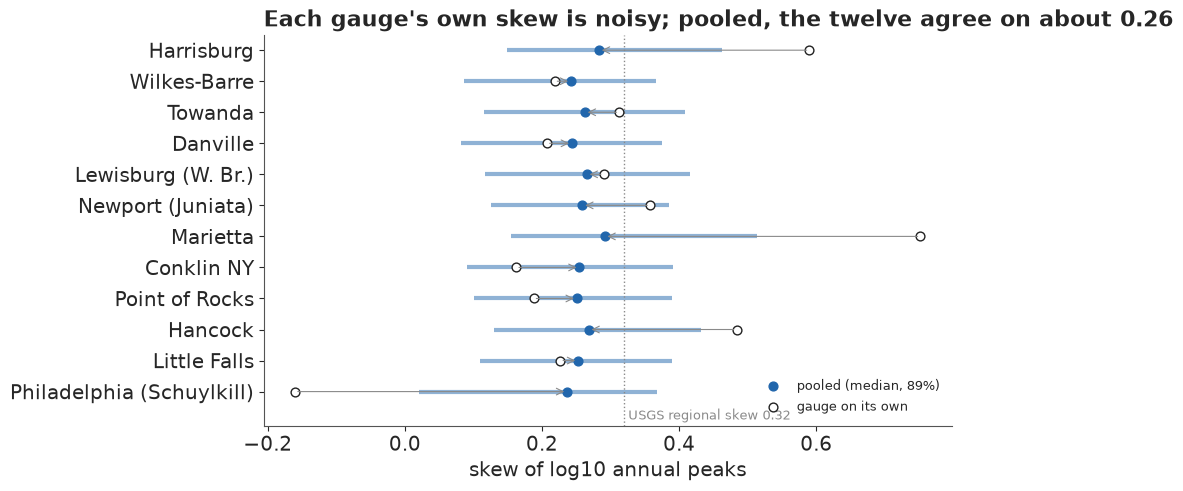

In [20]:
st_skew = np.array([stats.skew(x["q"], bias=False) for x in GAUGES])
gam_p = ALL["stationary"]["gamma"]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
yy = np.arange(len(GAUGES))[::-1]
lo_, hi_ = np.quantile(gam_p, [0.055, 0.945], axis=0)
ax.hlines(yy, lo_, hi_, color=HI, lw=3, alpha=0.5)
ax.scatter(np.median(gam_p, 0), yy, color=HI, s=40, zorder=3, label="pooled (median, 89%)")
ax.scatter(st_skew, yy, facecolor="white", edgecolor=INK, s=40, zorder=3, label="gauge on its own")
for y_, a_, b_ in zip(yy, st_skew, np.median(gam_p, 0)):
    ax.annotate("", (b_, y_), (a_, y_), arrowprops=dict(arrowstyle="->", color=MUTED, lw=0.8))
ax.axvline(REG_SKEW, color=MUTED, ls=":", lw=1)
ax.text(REG_SKEW, -0.9, " USGS regional skew 0.32", fontsize=9.5, color=MUTED)
ax.set_ylim(-1.1, len(GAUGES) - 0.5)
ax.set_yticks(yy, [x["name"] for x in GAUGES])
ax.set_xlabel("skew of log10 annual peaks")
ax.legend(loc="lower right", fontsize=9.5)
ax.set_title("Each gauge's own skew is noisy; pooled, the twelve agree on about 0.26", loc="left");

On its own a gauge's sample skew ranges from below zero to about 0.75; with about a century of
peaks each, those values carry standard errors near 0.25. Pooled, every gauge lands between about
0.2 and 0.3. The threshold posteriors of the other gauges with several candidates do not all tell
Harrisburg's story. At Wilkes-Barre the smallest candidate, the 1809 flood at 95,200 cfs, gets no
weight, so its old record is complete only for the larger floods. At Hancock and on the Schuylkill
most of the weight falls on the smallest recorded flood, the 17C default of a complete record. The
convention holds at some gauges and fails at others, which is the case for leaving it to the
data.

In [21]:
thr_m = ALL["stationary"]["thr"].mean(axis=0)
for r, i in enumerate(S2["hgi"]):
    c = HIST[GAUGES[i]["site"]]["cands"]
    if len(c) > 1:
        print(f"{GAUGES[i]['name']:>26}: " + ", ".join(f"{X / 1e3:,.0f}k {w:.2f}"
                                                      for X, w in zip(c, thr_m[r])))

                Harrisburg: 385k 0.31, 417k 0.17, 482k 0.51, 573k 0.02
              Wilkes-Barre: 95k 0.00, 176k 0.55, 189k 0.33, 202k 0.12
                   Hancock: 110k 0.65, 160k 0.32, 220k 0.04
 Philadelphia (Schuylkill): 98k 0.92, 135k 0.08


## F · Is the river changing?

### A first look without a model

Before any trend model, the plainest check: the median log peak before and after 1950 at each
gauge, also with the "before" window cut to 1932-1949 so that every gauge is compared over the
same years (Lewisburg starts in 1940), and Kendall's rank correlation with time at Harrisburg.

In [22]:
rows = []
for x in GAUGES:
    b4, af, l90 = x["q"][x["wy"] < 1950], x["q"][x["wy"] >= 1950], x["q"][x["wy"] >= 1990]
    w32 = x["q"][(x["wy"] >= 1932) & (x["wy"] < 1950)]  # a window every gauge but one covers
    rows.append(dict(gauge=x["name"], first=int(x["wy"].min()), before=len(b4), after=len(af),
                     change=f"{10 ** (np.median(af) - np.median(b4)) - 1:+.0%}",
                     from_1932=f"{10 ** (np.median(af) - np.median(w32)) - 1:+.0%}",
                     since_1990=f"{10 ** (np.median(l90) - np.median(af)) - 1:+.0%}",
                     regulated=int(x["reg"].sum())))
RAW_CHG = pd.DataFrame(rows)
print(RAW_CHG.to_string(index=False))
tau = stats.kendalltau(HB["wy"], HB["q"])
print(f"Harrisburg Kendall tau {tau.statistic:.3f} (p = {tau.pvalue:.3f}); lower after 1950 at "
      f"{int((RAW_CHG.change.str.startswith('-')).sum())} of 12 gauges")

                    gauge  first  before  after change from_1932 since_1990  regulated
               Harrisburg   1891      59     75   -10%       -1%        -3%          0
             Wilkes-Barre   1891      59     76    -3%      -10%        +1%         46
                  Towanda   1893      56     76    -8%      -18%        -1%         46
                 Danville   1900      50     75   -14%      -11%        +6%          0
       Lewisburg (W. Br.)   1940      10     75   -19%      -19%        -2%         59
        Newport (Juniata)   1899      51     76   -15%       +3%        -1%         54
                 Marietta   1932      18     75    -2%       -2%        -1%          0
               Conklin NY   1913      37     76   -13%       -6%        +0%          0
           Point of Rocks   1895      55     76   -10%      -21%        -5%          0
                  Hancock   1933      17     76   -11%      -11%       -16%          0
             Little Falls   1931      19   

The median yearly peak is lower after 1950 at all 12 gauges, from 2% at Marietta to 19% on the
West Branch, and 10% at Harrisburg, including all seven gauges with no regulation code. The
windows differ, though: five gauges start in 1931-1940, so their "before" is a run of big-flood
years (1936, 1942, 1943, 1946). Over the common window 1932-1949, 11 of 12 gauges are lower
afterwards, but Harrisburg by only about 1% and the Juniata not at all, so much of Harrisburg's
drop is against 1891-1931, and the date 1950 is our choice, not a finding. Since 1990 the medians
at most gauges are within a few percent of their post-1950 values (Hancock is the exception):
more like a mid-century step than a steady slide, which matters for what we project.

### Three ways the river could have changed

We compare three shapes for the location, each with a partially pooled effect per gauge,
$\delta_g = \delta_R + s_\delta z_g$ ($\delta_R \sim N(0, 0.1)$, $s_\delta \sim$
HalfNormal(0.05)), in log10 units:

- **stationary**, $f(t) = 0$;
- **a linear decline after 1950**, $f(t) = \max(t - 1950, 0)/100$, so $\delta$ is the change per
  century;
- **a step at 1950**, $f(t) = 0.5 \cdot 1[t \ge 1950]$, scaled so that $\delta$ means the same at
  the middle of the period.

A fourth model adds a trend in the spread, $\log \sigma_{gt} = \log \sigma_g + \eta_g f(t)$, to
see whether the floods became more or less variable. The historic periods all end before 1950,
so their terms use the pre-1950 level $\mu_g$.

In [23]:
HINGE = np.maximum(WY - 1950, 0) / 100.0
STEP = 0.5 * (WY >= 1950)
ONES = np.ones(len(WY))
ALL["decline after 1950"] = fit(C2, "decline after 1950", NAMES2, target_accept=0.95, keep=("thr",),
                                f_t=HINGE, f_s=ZERO, w=ONES)
ALL["step at 1950"] = fit(C2, "step at 1950", NAMES2, target_accept=0.95, f_t=STEP, f_s=ZERO,
                          w=ONES)
ALL["decline + spread trend"] = fit(C2, "decline + spread trend", NAMES2, target_accept=0.95,
                                    f_t=HINGE, f_s=HINGE, w=ONES)
F_NOW = {"decline after 1950": 0.75, "step at 1950": 0.5, "decline + spread trend": 0.75}
for k in F_NOW:
    p = ALL[k]
    ft_now = F_NOW[k]
    print(f"{k:>24}: delta_R {p['delta_R'].mean():+.3f} ± {p['delta_R'].std():.3f}, "
          f"P(delta_R < 0) {(p['delta_R'] < 0).mean():.3f}, drop by 2025 "
          f"{1 - 10 ** (ft_now * p['delta_R'].mean()):.0%}; eta_R {p['eta_R'].mean():+.3f} ± "
          f"{p['eta_R'].std():.3f}")

decline after 1950: 17 s, 0 divergences , max r_hat 1.006, min ESS 736 (a)


step at 1950: 17 s, 2 divergences {'energy error': 1, 'support wall': 1}, max r_hat 1.005, min ESS 700 (a)


decline + spread trend: 23 s, 1 divergences {'support wall': 1}, max r_hat 1.012, min ESS 665 (a)
      decline after 1950: delta_R -0.066 ± 0.020, P(delta_R < 0) 0.999, drop by 2025 11%; eta_R -0.000 ± 0.301
            step at 1950: delta_R -0.058 ± 0.023, P(delta_R < 0) 0.996, drop by 2025 6%; eta_R -0.004 ± 0.305
  decline + spread trend: delta_R -0.066 ± 0.020, P(delta_R < 0) 0.999, drop by 2025 11%; eta_R +0.013 ± 0.082


All three fit as cleanly as the stationary model. The regional decline is $-0.066 \pm 0.020$
log10 units per century, about 14% per century or 11% from 1950 to 2025, with a posterior
probability above 0.99 that it is below zero. The two shapes agree at 2000, where both have
$f = 0.5$, not in 2025: the step's $\delta_R$ of $-0.058$ means a drop of about 6%, against 11% for
the decline, so the step leaves today's river higher. The spread trend $\eta_R$ is near zero with
a posterior sd of 0.08 against a prior sd of 0.3: the variability has not changed, only the level. (In the fits
without a spread trend $\eta$ simply samples its prior, as $\delta$ does in the stationary fit.)

### Failure 3: a centred location and a moving wall

E25 found that with plenty of data per group, centred group effects sample better than
non-centred ones, and E94 found the same. Each of our gauges has about a century of peaks, so the
first version of this model was centred, $\mu_g \sim N(a + b \log_{10} A_g, s_\mu)$. Here it is on
the decline model with 300 draws per chain. The seed is not the notebook's: the failure depends
on where the chains start, and in our trials two of five seeds failed and three sampled cleanly
(the non-centred model was clean at all five), so we run one that failed, chosen after seeing it
fail.

In [24]:
t0 = time.time()
M2c, _ = model_all(GAUGES, centred=True)
C2c = nutpie.compile_pymc_model(M2c)
TIMES["compile centred"] = time.time() - t0
cen = fit(C2c, "centred location, decline after 1950", NAMES2, target_accept=0.95, draws=300,
          seed=2, f_t=HINGE, f_s=ZERO, w=ONES)
print("divergences per chain, centred:", cen["chain_div"])
print("mean log density per chain, centred:", cen["chain_logp"].round(0),
      " non-centred:", ALL["decline after 1950"]["chain_logp"].round(0))
print(f"regional skew {cen['gamma_R'].mean():.2f} ± {cen['gamma_R'].std():.2f} "
      f"(non-centred: {ALL['decline after 1950']['gamma_R'].mean():.2f} ± "
      f"{ALL['decline after 1950']['gamma_R'].std():.2f})")
del M2c, C2c, cen

centred location, decline after 1950: 36 s, 598 divergences {'support wall': 596, 'energy error': 2}, max r_hat 2.968, min ESS 5 (delta)
divergences per chain, centred: [300   1 297   0]
mean log density per chain, centred: [-790.  267. -768.  268.]  non-centred: [233. 234. 233. 234.]
regional skew -0.06 ± 0.34 (non-centred: 0.26 ± 0.06)


Two chains find the posterior and two never do: their mean log density is about
1,000 units below the others', nearly every one of their 300 draws is a divergence ("Logp function
returned error code", the support wall), r_hat is about 3 and the smallest ESS is 5. How many
chains stick at this seed changes from run to run (we have also seen one). Pooled over chains,
the regional skew comes out near zero with an sd of about 0.3, against 0.26 ± 0.06; without the
clean fit to compare, only the per-chain log densities give the stuck chains away. A model that
fails at two seeds in five is worse than one that always fails: a single clean run proves
nothing. The cause is the moving support. nutpie's start jitter of up to one unit is, for a
centred $\mu_g$, one log10 unit, a tenfold change in flow, which puts many peaks outside that
gauge's support. A chain that starts against a wall that moves with $\mu$, $\sigma$ and $\gamma$
at once can stay there for the whole run. Non-centred, the jitter of $e_g$ is scaled by $s_\mu$,
and the start is more often well inside. E37 met the same wall in the GEV: where the support
depends on the parameters, choose the parameterisation by where the sampler starts as well as by
how much data each group has.

### Which shape fits best?

The models are compared on their predictions for the 1,351 gauged peaks by PSIS-LOO
(the historic terms inform the tail and are the same in every model). The pointwise
log-likelihood is computed in NumPy with `scipy.stats.pearson3`, and **stacking** (Yao, Vehtari,
Simpson & Gelman 2018) finds the mixture of their predictive distributions that predicts best.

In [25]:
def loo_ll(ll):
    """PSIS-LOO from a (draws, observations) log-likelihood computed in NumPy."""
    dummy = xr.Dataset({"x": (("chain", "draw"), np.zeros((4, 1000)))})
    dt = xr.DataTree.from_dict({"posterior": dummy,
                                "log_likelihood": xr.Dataset({"y": (("chain", "draw", "obs"),
                                                                    ll.reshape(4, 1000, -1))})})
    out = az.loo(dt, pointwise=True)
    out.log_weights = None
    return out


def ll_of(post, f_t, f_s):
    """Pointwise log-likelihood of the gauged peaks, (draws, peaks)."""
    gi = S2["gi"]
    loc = post["mu"][:, gi] + post["delta"][:, gi] * f_t
    scl = post["sigma"][:, gi] * np.exp(post["eta"][:, gi] * f_s)
    return stats.pearson3.logpdf(S2["q"], post["gamma"][:, gi], loc=loc, scale=scl)


def loo_of(post, f_t, f_s):
    return loo_ll(ll_of(post, f_t, f_s))


SHAPES = {"stationary": (ZERO, ZERO), "decline after 1950": (HINGE, ZERO),
          "step at 1950": (STEP, ZERO), "decline + spread trend": (HINGE, HINGE)}
ALL["stationary"]["delta"] = np.zeros_like(ALL["stationary"]["delta"])  # unused parameters: 0
for k in ("stationary", "decline after 1950", "step at 1950"):
    ALL[k]["eta"] = np.zeros_like(ALL[k]["eta"])
LOO = {k: loo_of(ALL[k], *SHAPES[k]) for k in SHAPES}
CMP = az.compare(LOO, method="stacking", round_to="none")  # unrounded: the weights are used below
print(CMP[["rank", "elpd", "elpd_diff", "dse", "p", "weight"]].round(1).to_string())
print("Pareto k > 0.7:", {k: int((v.pareto_k > 0.7).sum()) for k, v in LOO.items()})
W_PT = CMP["weight"].to_dict()
print("stacking weights:", {k: round(v, 3) for k, v in W_PT.items()})

                        rank   elpd  elpd_diff  dse     p  weight
decline after 1950         0  399.1        0.0  0.0  28.1     0.9
decline + spread trend     1  397.7       -1.4  0.5  30.3     0.0
step at 1950               2  396.7       -2.3  2.5  28.9     0.1
stationary                 3  393.0       -6.0  3.4  25.2     0.0
Pareto k > 0.7: {'stationary': 0, 'decline after 1950': 0, 'step at 1950': 0, 'decline + spread trend': 0}
stacking weights: {'decline after 1950': 0.863, 'decline + spread trend': 0.0, 'step at 1950': 0.137, 'stationary': 0.0}


Every Pareto $k$ is below 0.7, so the PSIS estimates can be trusted. The decline after 1950
predicts best, by about 6 ± 3.5 log units over the stationary model, and stacking gives it most
of the weight, the step at 1950 the rest, and the stationary model none. (The split moves by a
few hundredths between reruns, since nutpie's threads do not repeat a run bit for bit.)
The spread trend adds a parameter and nothing to the predictions, so it gets no weight either.
The difference between decline and step is small (about 2 ± 2.5). These standard errors treat
the 1,351 peaks as independent, which the twelve gauges are not; we come back to that below.

### Twelve gauges, one pooled change

The percent change in the typical yearly peak from 1950 to 2025, $10^{0.75\,\delta_g} - 1$, at
each gauge:

P(lower) 0.91-0.99; median change by gauge: {'Harrisburg': '-11%', 'Wilkes-Barre': '-9%', 'Towanda': '-11%', 'Danville': '-11%', 'Lewisburg (W. Br.)': '-12%', 'Newport (Juniata)': '-12%', 'Marietta': '-11%', 'Conklin NY': '-11%', 'Point of Rocks': '-11%', 'Hancock': '-12%', 'Little Falls': '-11%', 'Philadelphia (Schuylkill)': '-9%'}


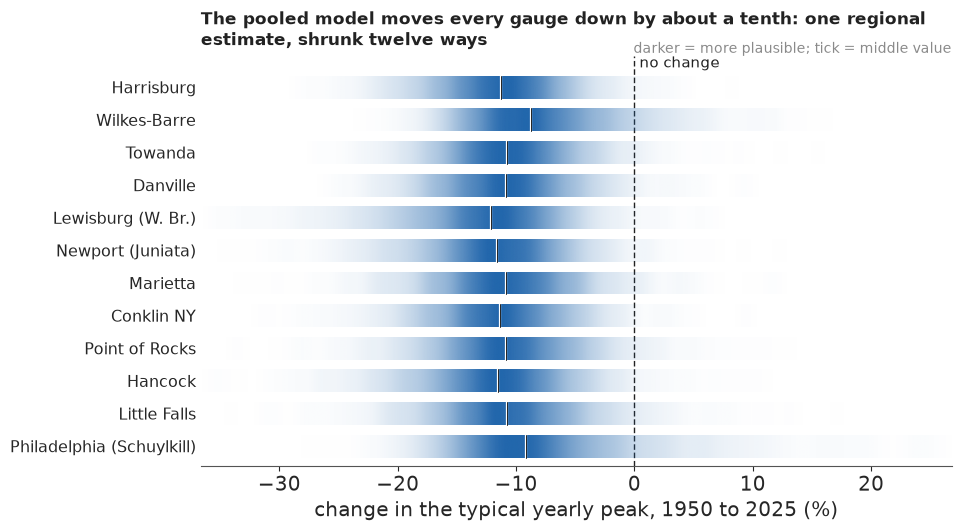

In [26]:
dl = ALL["decline after 1950"]["delta"]
chg = (10 ** (0.75 * dl) - 1) * 100
P_DOWN = (dl < 0).mean(axis=0)
fig, ax = plt.subplots(figsize=(9.5, 5.2))
pub.gradient_intervals(ax, [chg[:, i] for i in range(len(GAUGES))], [x["name"] for x in GAUGES],
                       ref=0, ref_label="no change",
                       xlabel="change in the typical yearly peak, 1950 to 2025 (%)",
                       title="The pooled model moves every gauge down by about a tenth: one "
                             "regional estimate, shrunk twelve ways")
print(f"P(lower) {P_DOWN.min():.2f}-{P_DOWN.max():.2f}; median change by gauge:", end=" ")
print({x["name"]: f"{np.median(chg[:, i]):+.0f}%" for i, x in enumerate(GAUGES)})

In the pooled model each gauge is below its 1950 level with probability 0.91 to 0.99. The strips
look alike largely because of the pooling: with $s_\delta \sim$ HalfNormal(0.05) the model
expects the gauges to have changed by similar amounts, so this display shows twelve shrunken
copies of one regional estimate rather than twelve separate confirmations, and the per-gauge
probabilities are too sure for the reason the next sections measure.

### Dams?

Five gauges carry regulation codes for decades: Wilkes-Barre and Towanda from 1980, the West
Branch from 1966, the Juniata from 1972 and the Schuylkill for 1979-2019. If flood-control dams
were the whole story, dropping the regulated peaks (weight 0) should remove much of the decline.

In [27]:
noreg = fit(C2, "decline, regulated peaks dropped", NAMES2, target_accept=0.95, f_t=HINGE, f_s=ZERO,
            w=1.0 - REG)
print(f"{int(REG.sum())} regulated peaks dropped: delta_R {noreg['delta_R'].mean():+.2f} ± "
      f"{noreg['delta_R'].std():.2f}, P(< 0) {(noreg['delta_R'] < 0).mean():.2f}")
del noreg

decline, regulated peaks dropped: 37 s, 159 divergences {'support wall': 158, 'energy error': 1}, max r_hat 1.004, min ESS 726 (s_mu)
246 regulated peaks dropped: delta_R -0.07 ± 0.03, P(< 0) 1.00


Without the 246 regulated peaks the regional decline is about as large (about $-0.07$) and still
almost certainly below zero; with well over a hundred divergences at the support wall, we read
it only as a rough check. It also tests less than it seems: the pooled decline is carried by the
gauges that keep their peaks, Harrisburg among them, which carries no code although it sits
below several reservoirs. So the check cannot rule out dams. Regrown forests and fewer ice jams
push the same way; heavier rain pushes the other. These data cannot separate the causes, the
main reason for low confidence in what follows.

### Twelve witnesses, or about two?

The trend models treat the twelve gauges' yearly peaks as independent given the parameters, but
a wet year is wet for all of them: 1936, 1972 and 2011 sent nearly every gauge to the top of its
record. The cell measures the correlation of log peaks over 1932-2024 and turns its average
$\bar\rho$ into Kish's effective number of independent gauges, $n/(1 + (n - 1)\bar\rho)$.

In [28]:
wide = (PEAKS[PEAKS.historic == 0]
        .pivot_table(index="water_year", columns="site_no", values="peak_cfs")
        .loc[1932:2024, ORDER])
R_g = np.log10(wide).corr().to_numpy()
R_up = R_g[np.triu_indices(len(ORDER), 1)]
RHO = R_up.mean()
N_EFF = len(ORDER) / (1 + (len(ORDER) - 1) * RHO)
print(f"correlation of yearly log peaks between gauges: mean {RHO:.2f} "
      f"(range {R_up.min():.2f}-{R_up.max():.2f}); effective independent gauges {N_EFF:.1f}; "
      f"sd inflation for a shared change about {np.sqrt(len(ORDER) / N_EFF):.1f}x")

correlation of yearly log peaks between gauges: mean 0.56 (range 0.19-1.00); effective independent gauges 1.7; sd inflation for a shared change about 2.7x


The answer is sobering. Neighbouring Susquehanna gauges often correlate at 0.9 and
more, Harrisburg and Marietta at 1.00, and even the Potomac and the Schuylkill share some storms;
on average the correlation is about 0.56, so for a change they all share the twelve gauges are
worth fewer than two independent ones. The regional decline's posterior sd of 0.020 is then too
small by a factor of about 2.7, and its "above 0.99" too sure.

The same holds for the LOO comparison, and there it can be fixed directly: leave out one **water
year** at a time, all twelve gauges together, instead of one peak. A shared storm then counts once.
We sum the pointwise log-likelihood over the gauges in each year and run PSIS-LOO and stacking on
the 135 year totals.

In [29]:
YRS, YI = np.unique(WY, return_inverse=True)


def by_year(ll):
    """Sum a (draws, peaks) log-likelihood over the gauges of each water year."""
    out = np.zeros((ll.shape[0], len(YRS)))
    np.add.at(out.T, YI, ll.T)
    return out


LOO_Y = {k: loo_ll(by_year(ll_of(ALL[k], *SHAPES[k]))) for k in SHAPES}
CMP_Y = az.compare(LOO_Y, method="stacking", round_to="none")
print(CMP_Y[["rank", "elpd", "elpd_diff", "dse", "p", "weight"]].round(1).to_string())
print("years with Pareto k > 0.7:",
      {k: [int(YRS[j]) for j in np.flatnonzero(np.asarray(v.pareto_k) > 0.7)] for k, v in LOO_Y.items()})
W = CMP_Y["weight"].to_dict()
print("stacking weights, by year:", {k: round(v, 3) for k, v in W.items()})

                        rank   elpd  elpd_diff  dse     p  weight
decline after 1950         0  395.9        0.0  0.0  33.7     0.5
step at 1950               1  393.7       -2.2  6.2  34.4     0.1
decline + spread trend     2  392.5       -3.4  0.9  39.7     0.0
stationary                 3  391.8       -4.2  8.6  27.4     0.4
years with Pareto k > 0.7: {'stationary': [1972], 'decline after 1950': [1972], 'step at 1950': [1965], 'decline + spread trend': [1965, 1969]}
stacking weights, by year: {'decline after 1950': 0.526, 'step at 1950': 0.122, 'decline + spread trend': 0.0, 'stationary': 0.352}


Left out by year, the decline still predicts best, but its lead over no change shrinks to about
4 log units and its standard error grows to about 9, two and a half times the pointwise one, as
the correlation predicted: the stationary and decline models can no longer be told apart.
Stacking now gives the decline about half the weight, the stationary model about a third and the
step the rest. One or two years (1972, 1965, 1969) have Pareto $k$ just above 0.7, so those year
totals are approximate. **These year-blocked weights are the ones we use for the public
numbers.**

A second check asks the one gauge the public question is about. We fit Harrisburg alone, with its
history, each of the three shapes, and the neighbours' skew as its prior. To keep Harrisburg's own
data out of that prior, it comes from the same stationary model fitted to the other eleven gauges.

In [30]:
t0 = time.time()
M11, S11 = model_all(GAUGES[1:])
C11 = nutpie.compile_pymc_model(M11)
TIMES["compile eleven gauges"] = time.time() - t0
n11 = len(S11["q"])
p11 = fit(C11, "eleven gauges (no Harrisburg), stationary", NAMES2, target_accept=0.95,
          f_t=np.zeros(n11), f_s=np.zeros(n11), w=np.ones(n11))
SK_C = float(p11["gamma_R"].mean())
SK_S = float(np.sqrt(p11["gamma_R"].var() + (p11["s_R"] ** 2).mean()))
del M11, S11, C11, p11
HW = HB["wy"]
HB_SHAPES = {"stationary": (np.zeros(len(HW)), 0.0),
             "decline after 1950": (np.maximum(HW - 1950, 0) / 100.0, 0.75),
             "step at 1950": (0.5 * (HW >= 1950), 0.5)}
HB1 = {k: fit(C1, f"Harrisburg alone, {k}", ONE_NAMES + ["delta"], skew_centre=SK_C,
              skew_sd=SK_S, hist_on=1.0, f_t=ft) for k, (ft, _) in HB_SHAPES.items()}
LOO1 = {}
for k, (ft, _) in HB_SHAPES.items():
    p = HB1[k]
    LOO1[k] = loo_ll(stats.pearson3.logpdf(HB["q"], p["gamma"][:, None],
                                           loc=p["mu"][:, None] + p["delta"][:, None] * ft,
                                           scale=p["sigma"][:, None]))
CMP1 = az.compare(LOO1, method="stacking", round_to="none")
print(f"skew prior from the other eleven gauges: {SK_C:.2f} ± {SK_S:.2f}")
print(CMP1[["elpd", "elpd_diff", "dse", "weight"]].round(2).to_string())
for k in ("decline after 1950", "step at 1950"):
    d_ = HB1[k]["delta"]
    print(f"Harrisburg alone, {k}: delta {d_.mean():+.3f} ± {d_.std():.3f}, P(< 0) "
          f"{(d_ < 0).mean():.3f}")
P_DOWN_HB = float((HB1["decline after 1950"]["delta"] < 0).mean())
P_DOWN_HB_STEP = float((HB1["step at 1950"]["delta"] < 0).mean())

eleven gauges (no Harrisburg), stationary: 11 s, 5 divergences {'support wall': 4, 'energy error': 1}, max r_hat 1.010, min ESS 468 (a)


Harrisburg alone, stationary: 0 s, 0 divergences , max r_hat 1.003, min ESS 4054 (sigma)


Harrisburg alone, decline after 1950: 0 s, 0 divergences , max r_hat 1.000, min ESS 2485 (delta)


Harrisburg alone, step at 1950: 1 s, 0 divergences , max r_hat 1.001, min ESS 2451 (mu)


skew prior from the other eleven gauges: 0.24 ± 0.12
                     elpd  elpd_diff   dse  weight
decline after 1950  55.73       0.00  0.00     1.0
step at 1950        54.54      -1.19  1.00     0.0
stationary          54.43      -1.30  1.51     0.0
Harrisburg alone, decline after 1950: delta -0.079 ± 0.048, P(< 0) 0.949
Harrisburg alone, step at 1950: delta -0.044 ± 0.047, P(< 0) 0.834


Harrisburg on its own puts the decline at about $-0.08 \pm 0.05$ per century, as large as the
regional estimate but more than twice as uncertain, as the correlation predicted: under a steady
decline the probability that its peaks are lower now is about 95%, not 99.9%, and under a step
about 85%. LOO at one gauge barely separates the three shapes (differences of 1-1.5 with
standard errors of about the same size). Stacking still puts all the weight on the decline, but on
differences this small that choice says little, so below we show all three Harrisburg-alone
shapes rather than one.

### What we project, and why

A trend model says where the river is *now*. Extending its line 30 years, as if the decline will
continue at the same rate, is a separate bet, and the data since 1990 do not support it. So
**for 2025-2054 we hold each model's level at its 2025 value** (the decline model at $f = 0.75$,
the step at $0.5$) and mix the models by their year-blocked stacking weights. Beside it we show
the alternatives: each model on its own, the extrapolated line, the river back at its pre-1950
level ($f = 0$ in the decline and step models), the mixture with the pointwise weights that treat
the gauges as independent, and Harrisburg fitted alone under each shape.

For a draw $s$ with today's location $\mu^{(s)}_{2025}$, the chance of beating a flow $x$ is
$P_{30}^{(s)}(x) = 1 - F^{(s)}(x)^{30}$, and its posterior mean is the predictive probability we
report.

In [31]:
F_TODAY = {"stationary": (0.0, 0.0), "decline after 1950": (0.75, 0.0), "step at 1950": (0.5, 0.0),
           "decline + spread trend": (0.75, 0.75)}


def today(k, i=0):
    """Gauge i's location, scale and skew at the 2025 level, per draw."""
    p, (ft, fs) = ALL[k], F_TODAY[k]
    return (p["mu"][:, i] + p["delta"][:, i] * ft, p["sigma"][:, i] * np.exp(p["eta"][:, i] * fs),
            p["gamma"][:, i])


TODAY = {k: today(k) for k in W}


def mixture(weights, parts, seed):
    """Draws of (location, scale, skew) from a mixture of models with the given weights."""
    w_arr = np.array([weights[k] for k in parts])
    pick = np.random.default_rng(seed).choice(len(parts), size=4000, p=w_arr / w_arr.sum())
    return tuple(np.choose(pick, [parts[k][j] for k in parts]) for j in range(3))


STACK = mixture(W, TODAY, 7)
STACK_PT = mixture(W_PT, TODAY, 7)  # pointwise weights: the gauges treated as independent
PRE = mixture(W, {k: (ALL[k]["mu"][:, 0], ALL[k]["sigma"][:, 0], ALL[k]["gamma"][:, 0])
                  for k in W}, 7)  # the same mixture at f = 0
HB_TODAY = {k: (HB1[k]["mu"] + HB1[k]["delta"] * f_, HB1[k]["sigma"], HB1[k]["gamma"])
            for k, (_, f_) in HB_SHAPES.items()}


def p30_extrap(x, k="decline after 1950"):
    p = ALL[k]
    lf = sum(stats.pearson3.logcdf(np.log10(x), p["gamma"][:, 0],
                                   loc=p["mu"][:, 0] + p["delta"][:, 0] * max(t - 1950, 0) / 100,
                                   scale=p["sigma"][:, 0]) for t in range(2025, 2055))
    return -np.expm1(lf)


EVENTS = {"beats the textbook 100-year flow": Q100_TXT, "water 2 ft above that line": Q_2FT,
          "a flood as big as Lee (2011)": 5.9e5, "a flood as big as Agnes (1972)": 1.02e6}
DR, rows = {}, []
for ev, x in EVENTS.items():
    DR[ev] = {"stationary": p30(x, *TODAY["stationary"]),
              "decline, held": p30(x, *TODAY["decline after 1950"]),
              "decline, extrapolated": p30_extrap(x),
              "step, held": p30(x, *TODAY["step at 1950"]),
              "pre-1950 level": p30(x, *PRE),
              "stacked, gauges independent": p30(x, *STACK_PT),
              **{f"Harrisburg alone, {k}": p30(x, *HB_TODAY[k]) for k in HB_SHAPES},
              "stacked": p30(x, *STACK)}
    rows.append({"event": ev, "flow": f"{x:,.0f}",
                 **{k: f"{v.mean():.1%}" for k, v in DR[ev].items()},
                 "stacked 89%": f"{np.quantile(DR[ev]['stacked'], 0.055):.1%}-"
                                f"{np.quantile(DR[ev]['stacked'], 0.945):.1%}"})
print("chance of at least one, 2025-2054, at Harrisburg (posterior mean):")
print(pd.DataFrame(rows).set_index("event").T.to_string())
HB_P = [DR["beats the textbook 100-year flow"][f"Harrisburg alone, {k}"].mean() for k in HB_SHAPES]
print(f"Harrisburg alone, textbook flow: {min(HB_P):.1%} to {max(HB_P):.1%} across the three shapes")
aep_txt = -np.expm1(stats.pearson3.logcdf(np.log10(Q100_TXT), STACK[2], loc=STACK[0],
                                         scale=STACK[1])).mean()
print(f"today's chance per year of beating the textbook flow: {aep_txt:.2%} "
      f"(1 in {1 / aep_txt:.0f})")
qq_today = q100(*STACK)
print(f"stacked 100-year flow at today's level: {np.median(qq_today):,.0f} "
      f"({np.quantile(qq_today, 0.055):,.0f} - {np.quantile(qq_today, 0.945):,.0f})")

chance of at least one, 2025-2054, at Harrisburg (posterior mean):
event                                beats the textbook 100-year flow water 2 ft above that line a flood as big as Lee (2011) a flood as big as Agnes (1972)
flow                                                          714,792                    835,078                      590,000                      1,020,000
stationary                                                      14.4%                       5.6%                        38.5%                           1.5%
decline, held                                                    8.1%                       3.0%                        24.1%                           0.7%
decline, extrapolated                                            7.1%                       2.6%                        21.5%                           0.6%
step, held                                                      11.8%                       4.5%                        32.9%                       

At today's level, stacked by year, the chance that the river beats the textbook 100-year flow at
least once in 2025-2054 is about 11%, with an 89% range for that chance of about 3% to
22%. The models on their own span the answer: about 8% if the decline is real and holds,
about 12% under the step, about 14% if the river has not changed. Back at its pre-1950 level it
would be about 16%; with the line extrapolated, about 7%. With the pointwise weights, which treat
the gauges as independent and give no change no weight, it would be about 9%. Whether the drop is
real matters more than whether it lasts. Harrisburg fitted alone spans 8% to 15% across
its three shapes: close to the twelve-gauge answer if the decline is real, higher if not. Water 2
ft above the line comes to about 4%, a Lee-sized flood to about 30%, an Agnes to about
1%. The stacked 100-year flow at today's level is about 600,000 cfs: by today's river, the
textbook flow is roughly a 1-in-250-year flood.

## G · Explaining it to everyone

### The statistician's plot

A hydrologist would summarise parts D and E with a **return-level plot**: the flow against its
return period on log axes, the fitted curve with its uncertainty, and the observed peaks at
plotting positions. With historic floods the positions need Hirsch & Stedinger's (1987, *Water
Resources Research*) formula: above a threshold (here 482,000 cfs) the floods rank among all 238
years of the gauged and historic record, below it the gauged peaks share the rest of the
probability.

Agnes plots at a return period of 256 years


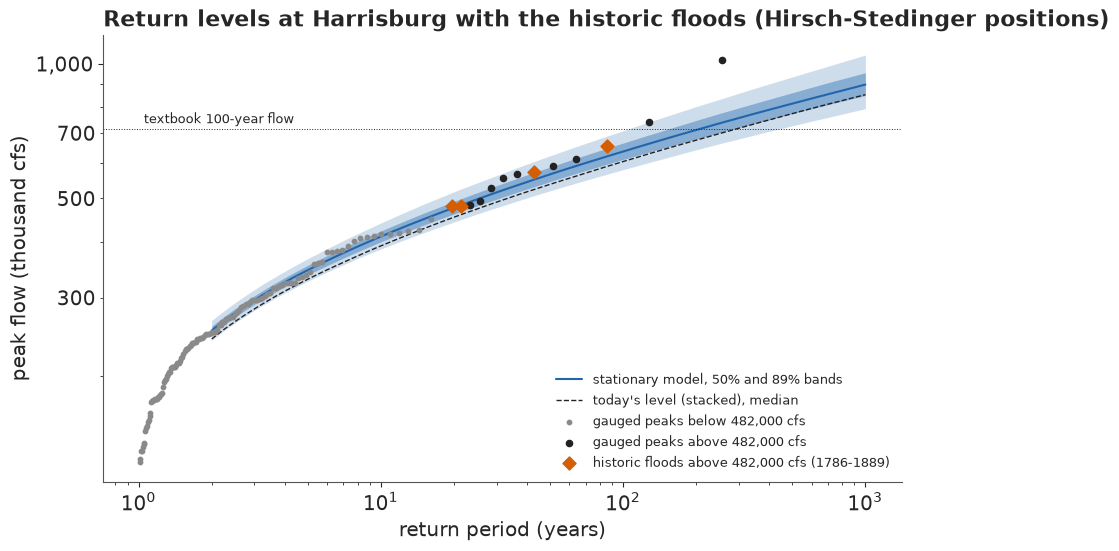

In [32]:
aep = np.geomspace(0.5, 0.001, 80)
RL = np.array([q100(*TODAY["stationary"], p=1 - a_) for a_ in aep])
RL_T = np.array([np.median(q100(*STACK, p=1 - a_)) for a_ in aep])
X_HS = 482e3
hv, sv_ = HB_HIST.peak_cfs.values, HB_SYS.peak_cfs.values
above = np.sort(np.r_[hv[hv >= X_HS], sv_[sv_ >= X_HS]])[::-1]
n_tot = T_HIST + n_sys
pe = len(above) / n_tot
pa = pe * np.arange(1, len(above) + 1) / (len(above) + 1)
below = np.sort(sv_[sv_ < X_HS])[::-1]
pb = pe + (1 - pe) * np.arange(1, len(below) + 1) / (len(below) + 1)
is_h = np.isin(above, hv)
fig, ax = plt.subplots(figsize=(9, 5.4))
for lo_q, hi_q, al in ((0.055, 0.945, 0.22), (0.25, 0.75, 0.4)):
    ax.fill_between(1 / aep, np.quantile(RL, lo_q, axis=1) / 1e3,
                    np.quantile(RL, hi_q, axis=1) / 1e3,
                    color=HI, alpha=al, lw=0)
ax.plot(1 / aep, np.median(RL, axis=1) / 1e3, color=HI, label="stationary model, 50% and 89% bands")
ax.plot(1 / aep, RL_T / 1e3, color=INK, lw=1, ls="--", label="today's level (stacked), median")
ax.scatter(1 / pb, below / 1e3, s=10, color=MUTED, zorder=3,
           label=f"gauged peaks below {X_HS / 1e3:,.0f},000 cfs")
ax.scatter(1 / pa[~is_h], above[~is_h] / 1e3, s=20, color=INK, zorder=4,
           label=f"gauged peaks above {X_HS / 1e3:,.0f},000 cfs")
ax.scatter(1 / pa[is_h], above[is_h] / 1e3, s=44, marker="D", color=LO, zorder=5,
           label=f"historic floods above {X_HS / 1e3:,.0f},000 cfs (1786-1889)")
ax.axhline(Q100_TXT / 1e3, color=INK, lw=0.7, ls=":")
ax.text(1.05, Q100_TXT / 1e3 + 10, "textbook 100-year flow", fontsize=9.5, ha="left", va="bottom")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("return period (years)")
ax.set_ylabel("peak flow (thousand cfs)")
ax.legend(loc="lower right", fontsize=9.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_formatter(plt.FuncFormatter(
    lambda v, _: f"{v:,.0f}" if v in (150, 300, 500, 700) else ""))
ax.set_title("Return levels at Harrisburg with the historic floods (Hirsch-Stedinger positions)",
             loc="left")
print(f"Agnes plots at a return period of {1 / pa[0]:.0f} years")

The same fit can be checked by number. Under the model, each gauged peak lands above its year's
10-year flow with probability 0.10 and above its 50-year flow with probability 0.02, so for each
posterior draw we count the share that do, against the spread a binomial count would have.

In [33]:
gi = S2["gi"]
for k in ("stationary", "decline after 1950"):
    p, (ft, fs) = ALL[k], SHAPES[k]
    u = stats.pearson3.cdf(S2["q"], p["gamma"][::4][:, gi],
                           loc=p["mu"][::4][:, gi] + p["delta"][::4][:, gi] * ft,
                           scale=p["sigma"][::4][:, gi] * np.exp(p["eta"][::4][:, gi] * fs))
    for a_, n_, lab in ((0.10, len(gi), "all gauges"), (0.02, len(gi), "all gauges"),
                        (0.02, int((gi == 0).sum()), "Harrisburg")):
        uu = u if lab == "all gauges" else u[:, gi == 0]
        n_up = (uu > 1 - a_).sum(axis=1)
        lo_b, hi_b = stats.binom.ppf([0.055, 0.945], n_, a_)
        print(f"{k:>18}, {lab:>10}: above the {1 / a_:.0f}-year flow {np.median(n_up):.0f} of {n_} "
              f"(expected {a_ * n_:.0f}, 89% binomial range {lo_b:.0f}-{hi_b:.0f})")
del u, uu

        stationary, all gauges: above the 10-year flow 138 of 1351 (expected 135, 89% binomial range 118-153)
        stationary, all gauges: above the 50-year flow 30 of 1351 (expected 27, 89% binomial range 19-35)
        stationary, Harrisburg: above the 50-year flow 5 of 134 (expected 3, 89% binomial range 0-5)


decline after 1950, all gauges: above the 10-year flow 138 of 1351 (expected 135, 89% binomial range 118-153)
decline after 1950, all gauges: above the 50-year flow 32 of 1351 (expected 27, 89% binomial range 19-35)
decline after 1950, Harrisburg: above the 50-year flow 6 of 134 (expected 3, 89% binomial range 0-5)


The plot and the counts are the posterior predictive check of the fit. Over the twelve gauges
the counts above the 10- and 50-year flows sit inside their binomial ranges, so the log-Pearson
III holds the body and the upper tail of the record. Harrisburg's top is a little heavier than
expected (5 or 6 of 134 peaks above the 50-year flow, against about 3 and a range of 0-5), and on
the plot the historic floods sit among the gauged ones while Agnes, at about 260 years, is the one
point far above the band, with 1936 at its edge.

For anyone but a hydrologist the plot answers a question they did not ask. "Return period"
invites the "once a century" reading, the axes are logarithmic, and the chance over the years
someone will live in a house appears nowhere. The bands also look like hard limits: readers judge
values just inside a band as far more likely than values just outside (Correll & Gleicher 2014).

### Chance-of bars

The public display turns the posterior into the probability of named events over a stated
period, and puts them on one 0-100% axis. Probabilistic forecasts of this kind lead to better
decisions and more trust than single-value forecasts, and soften the loss of trust when a
forecast misses (Joslyn & LeClerc 2012, *J. Experimental Psychology: Applied*). Each bar is the
predictive probability with its calibrated word and its 89% range; under each bar a thin
**gradient whisker** shows how sure we are of that probability, darker where it is more
plausible, instead of an error bar with hard ends. Two grey **reference bars** below a rule give
the numbers anchors: what "1-in-100 a year" and "1-in-500 a year" add up to over 30 years.

Over a 30-year mortgage at Harrisburg, a flood beyond the textbook 100-year mark is unlikely (about 11%, between 3% and 22%), well under the 26% its name implies
It is *unlikely* (11%) that the river beats the textbook 100-year flow at least once in 2025-2054. We have *low confidence* in that figure: its range runs from *very unlikely* (3%) to *unlikely* (22%), and it weighs a drop of unknown cause (at Harrisburg alone 95% likely if steady, 85% if a step) against no change (about 14%).


{'beats the textbook 100-year flow': '10.8% (unlikely)', 'water 2 ft above that line': '4.1% (very unlikely)', 'a flood as big as Lee (2011)': '30.4% (unlikely)', 'a flood as big as Agnes (1972)': '1.1% (very unlikely)'}
in natural frequencies: 1 in 9 (textbook), 1 in 95 (Agnes)


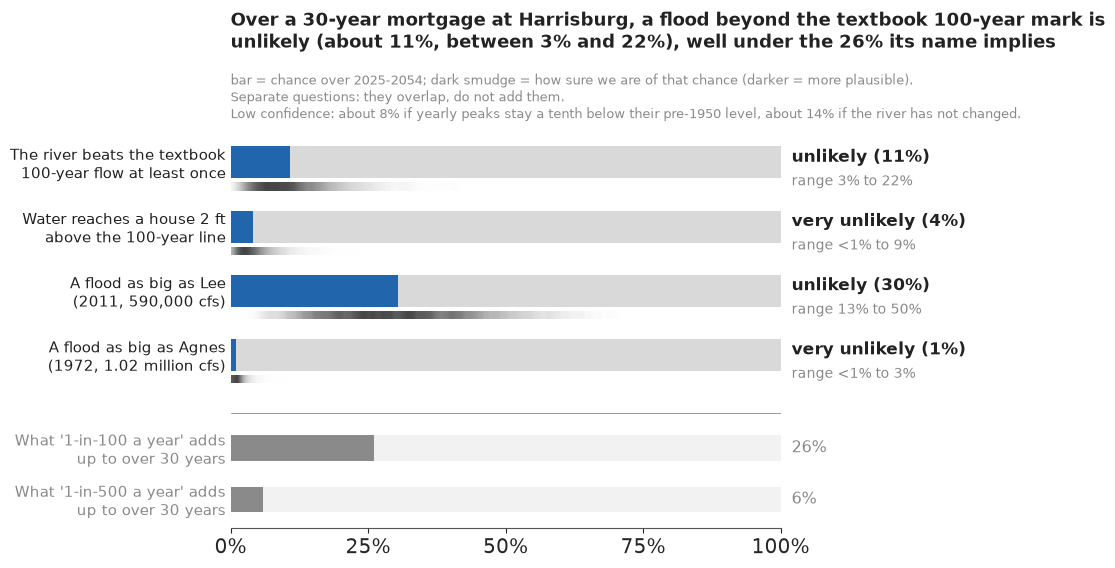

In [34]:
def chance_bars(ax, items, refs, title, key=True, note=""):  # local; the shared module has none
    """Chance-of bars: items = [(label, P30 draws)]; refs = [(label, p)], grey, below a rule."""
    for i, (lab, v) in enumerate(items):
        p = float(np.mean(v))
        ax.barh(i, 1, color=LIGHT, height=0.5, zorder=1)
        ax.barh(i, p, color=HI, height=0.5, zorder=2)
        dens = np.histogram(v, bins=200, range=(0, 1))[0].astype(float)
        dens = np.convolve(dens, np.ones(5) / 5, mode="same")
        img = np.zeros((1, 200, 4))
        img[..., :3] = to_rgb(INK)
        img[..., 3] = 0.85 * (dens / dens.max()) ** 0.8
        ax.imshow(img, extent=(0, 1, i + 0.31, i + 0.44), aspect="auto", zorder=3,
                  interpolation="bilinear", origin="lower")
        ax.text(1.02, i - 0.08, f"{pub.calibrated_word(p)} ({pct(p)})", va="center", fontsize=12,
                color=INK, weight="bold").set_in_layout(False)
        lo_v, hi_v = np.quantile(v, [0.055, 0.945])
        ax.text(1.02, i + 0.3, f"range {pct(lo_v)} to {pct(hi_v)}", va="center", fontsize=10,
                color=MUTED).set_in_layout(False)
    base = len(items) - 0.1
    ax.axhline(base, color=MUTED, lw=0.6)
    for j, (lab, p) in enumerate(refs):
        y = base + 0.55 + 0.8 * j
        ax.barh(y, 1, color="#f2f2f2", height=0.4)
        ax.barh(y, p, color=MUTED, height=0.4)
        ax.text(1.02, y, pub.fmt_pct(p), va="center", fontsize=11.5,
                color=MUTED).set_in_layout(False)
    ticks = list(range(len(items))) + [base + 0.55 + 0.8 * j for j in range(len(refs))]
    ax.set_yticks(ticks, [lab for lab, _ in items] + [lab for lab, _ in refs], fontsize=11)
    for t_, c_ in zip(ax.get_yticklabels(), [INK] * len(items) + [MUTED] * len(refs)):
        t_.set_color(c_)
    ax.set_xlim(0, 1)
    ax.set_ylim(base + 0.55 + 0.8 * (len(refs) - 1) + 0.45, -0.75)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ["0%", "25%", "50%", "75%", "100%"])
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)
    if key:
        ax.text(0, -0.62, "bar = chance over 2025-2054; dark smudge = how sure we are of that "
                "chance (darker = more plausible).\nSeparate questions: they overlap, do not add "
                "them." + (f"\n{note}" if note else ""),
                fontsize=9.5, color=MUTED, va="bottom").set_in_layout(False)
    ax.set_title(wrap(title, 84), loc="left", fontsize=13, color=INK, pad=48 if note else 34)


EV_LAB = {"beats the textbook 100-year flow":
          "The river beats the textbook\n100-year flow at least once",
          "water 2 ft above that line": "Water reaches a house 2 ft\nabove the 100-year line",
          "a flood as big as Lee (2011)": "A flood as big as Lee\n(2011, 590,000 cfs)",
          "a flood as big as Agnes (1972)": "A flood as big as Agnes\n(1972, 1.02 million cfs)"}
REFS = [("What '1-in-100 a year' adds\nup to over 30 years", 1 - 0.99**30),
        ("What '1-in-500 a year' adds\nup to over 30 years", 1 - 0.998**30)]
def about5(p):
    """A probability rounded to the nearest 5%, the precision the prose quotes."""
    return f"{5 * round(p * 20):.0f}%"


HEAD = DR["beats the textbook 100-year flow"]["stacked"]
P_HEAD, (HLO, HHI) = HEAD.mean(), np.quantile(HEAD, [0.055, 0.945])
P_STAT = DR["beats the textbook 100-year flow"]["stationary"].mean()
P_DECL = DR["beats the textbook 100-year flow"]["decline, held"].mean()
HEAD_TITLE = (f"Over a 30-year mortgage at Harrisburg, a flood beyond the textbook 100-year mark "
              f"is {pub.calibrated_word(P_HEAD)} (about {P_HEAD:.0%}, between {HLO:.0%} and "
              f"{HHI:.0%}), well under the 26% its name implies")
HEAD_NOTE = (f"Low confidence: about {P_DECL:.0%} if yearly peaks stay a tenth below their "
             f"pre-1950 level, about {P_STAT:.0%} if the river has not changed.")


def headline_figure(which="stacked", title=HEAD_TITLE):
    fig, ax = plt.subplots(figsize=(11, 6.0), layout="none")
    fig.subplots_adjust(left=0.22, right=0.72, top=0.77, bottom=0.08)
    chance_bars(ax, [(EV_LAB[e], DR[e][which]) for e in EVENTS], REFS, title, note=HEAD_NOTE)
    return fig


fig_top = headline_figure()
HEADLINE.update(fig_top)  # the copy at the top of the notebook
plt.close(fig_top)
headline_figure()
print(HEAD_TITLE)
w_lo, w_hi = pub.calibrated_word(HLO), pub.calibrated_word(HHI)
SURE = pub.how_sure(
    P_HEAD, "the river beats the textbook 100-year flow at least once in 2025-2054", "low",
    f"its range runs from *{w_lo}* ({HLO:.0%}) to *{w_hi}* ({HHI:.0%}), and it weighs a drop of "
    f"unknown cause (at Harrisburg alone {about5(P_DOWN_HB)} likely if steady, "
    f"{about5(P_DOWN_HB_STEP)} if a step) against no change (about {P_STAT:.0%})")
print(SURE)
HOW_SURE.update(Markdown("**How sure are we.** " + SURE))
print({e: f"{DR[e]['stacked'].mean():.1%} ({pub.calibrated_word(DR[e]['stacked'].mean())})"
       for e in EVENTS})
print(f"in natural frequencies: 1 in {1 / P_HEAD:.0f} (textbook), 1 in "
      f"{1 / DR['a flood as big as Agnes (1972)']['stacked'].mean():.0f} (Agnes)")

The figure answers the question in the first line people read: about 11 chances in 100 that
the river beats the textbook 100-year flow during the mortgage, against the 26% the label
implies. The smudge under each bar, and the range printed beside it, are the honest size of our
uncertainty about that chance; the bar itself is the single number to act on.

Four pitfalls were designed out. The events are nested (Agnes is above both lines), so the key
says not to add the bars. A 26% bar in the same blue would read as a fifth event, so the
reference bars are grey and below a rule. The word comes from the number, and where the range
crosses into the next word (the first bar and Lee's) the printed range shows it. And because the
figure will travel on its own, its key carries the low-confidence line with both model answers.

### What would change our mind

The chance-of bars rest on choices made in parts C-F. A strip of gradient intervals for the
100-year flow (drawn in place of error bars) shows what each piece of information did,
from the gauge alone to today's river.

{'Harrisburg alone, gauged years, vague skew': '725,655 (29.2%)', '+ the USGS regional skew prior': '714,924 (27.4%)', '+ the floods of 1786-1889': '660,766 (18.8%)', '+ 11 neighbouring gauges': '636,793 (14.4%)', "+ the decline since 1950, today's level": '576,556 (8.1%)', "a step at 1950 instead, today's level": '615,084 (11.8%)', 'the three weighted by year-blocked stacking': '604,743 (10.8%)', 'Harrisburg alone, with history, no change': '642,376 (15.2%)', 'Harrisburg alone, with history, its step': '623,751 (13.0%)', 'Harrisburg alone, with history, its decline': '572,183 (8.3%)'}


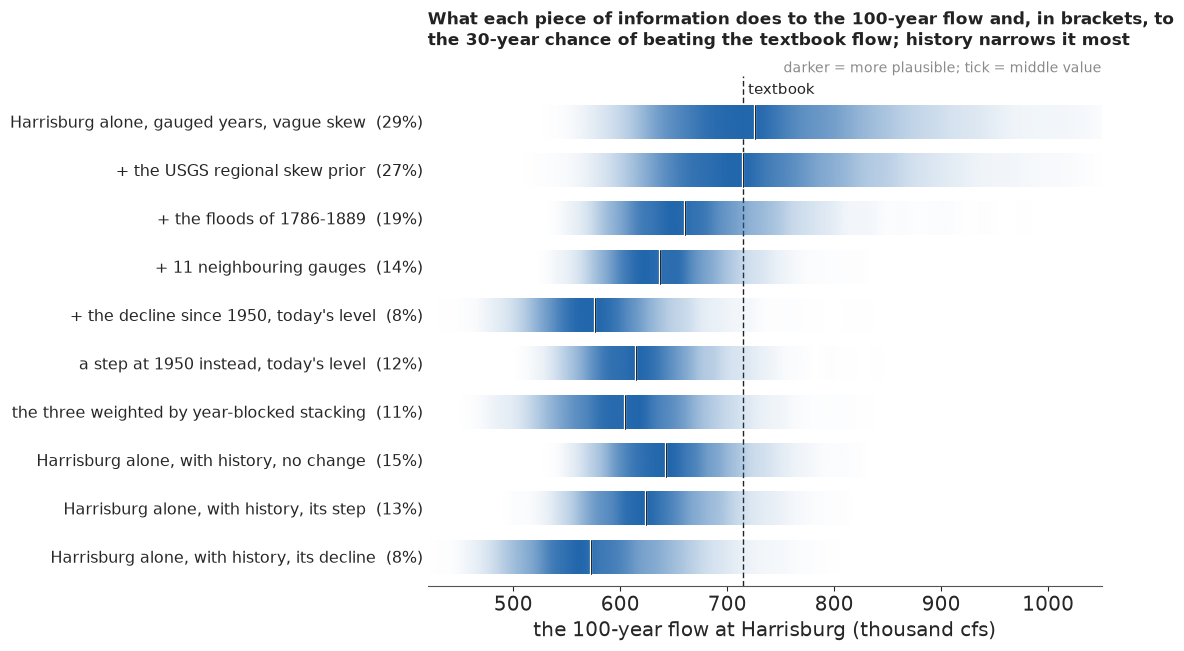

In [35]:
strips = [q100(ONE[k]["mu"], ONE[k]["sigma"], ONE[k]["gamma"]) for k in ONE if "intervals" not in k]
chances = [p30(Q100_TXT, ONE[k]["mu"], ONE[k]["sigma"], ONE[k]["gamma"]).mean()
           for k in ONE if "intervals" not in k]
labs = ["Harrisburg alone, gauged years, vague skew", "+ the USGS regional skew prior",
        "+ the floods of 1786-1889"]
for k, lab in (("stationary", "+ 11 neighbouring gauges"),
               ("decline after 1950", "+ the decline since 1950, today's level"),
               ("step at 1950", "a step at 1950 instead, today's level")):
    strips.append(q100(*TODAY[k]))
    chances.append(p30(Q100_TXT, *TODAY[k]).mean())
    labs.append(lab)
strips.append(q100(*STACK))
chances.append(P_HEAD)
labs.append("the three weighted by year-blocked stacking")
for k, lab in (("stationary", "no change"), ("step at 1950", "its step"),
               ("decline after 1950", "its decline")):
    strips.append(q100(*HB_TODAY[k]))
    chances.append(DR["beats the textbook 100-year flow"][f"Harrisburg alone, {k}"].mean())
    labs.append(f"Harrisburg alone, with history, {lab}")
fig, ax = plt.subplots(figsize=(11, 6.4))
pub.gradient_intervals(ax, [s / 1e3 for s in strips],
                       [f"{lab}  ({pct(c)})" for lab, c in zip(labs, chances)],
                       ref=Q100_TXT / 1e3, ref_label="textbook", xlim=(420, 1050),
                       xlabel="the 100-year flow at Harrisburg (thousand cfs)")
ax.set_title(wrap("What each piece of information does to the 100-year flow and, in brackets, to "
                  "the 30-year chance of beating the textbook flow; history narrows it most", 80),
             loc="left", fontsize=12.5, color=INK, pad=22)
print({lab: f"{np.median(s):,.0f} ({c:.1%})" for lab, s, c in zip(labs, strips, chances)})

The gauge alone leaves a long upper tail, reaching past 850,000 cfs. History cuts most of it off,
the neighbours narrow the rest, and the decline moves the whole strip left; the bracketed chances
fall with it, from about 29% to about 8%. If the post-1950 drop were a fluke, the answer would
move back to the "11 neighbouring gauges" row, about 14% instead of 11%. If the twelve gauges are worth less
than they seem, the last three rows, Harrisburg alone, give 8% to 15%: the answer moves
little if the decline is real, and back to the stationary number if it is not.

### Flood marks on a bridge pier

Harrisburg's old floods are remembered as marks: lines on walls and piers, each with a year. A
stylised pier with the six best-known marks (from the stages in the peak file) carries the story
to people who will never see a probability. In the animation, each frame is one possible next 30
years, drawn from the stacked posterior at today's level: its highest water rises against the
pier, and earlier frames stay as faint lines. This is a **hypothetical outcome plot** (Hullman,
Resnick & Adar 2015; Kale, Nguyen, Kay & Hullman 2019): the reader sees how often the water
reaches the line by watching it happen, at 0.6 s a frame, below the three flashes a second that
accessibility guidance forbids.

wrote E113_hundred_year_flood_next30.gif: 40 frames, 560x480 px, 0.4 MB
6 of 40 futures top the line; highest water 18.7-31.4 ft, middle 80% 20.8-28.0 ft; at the headline chance, 40 futures would put 1 to 8 above the line (89%)


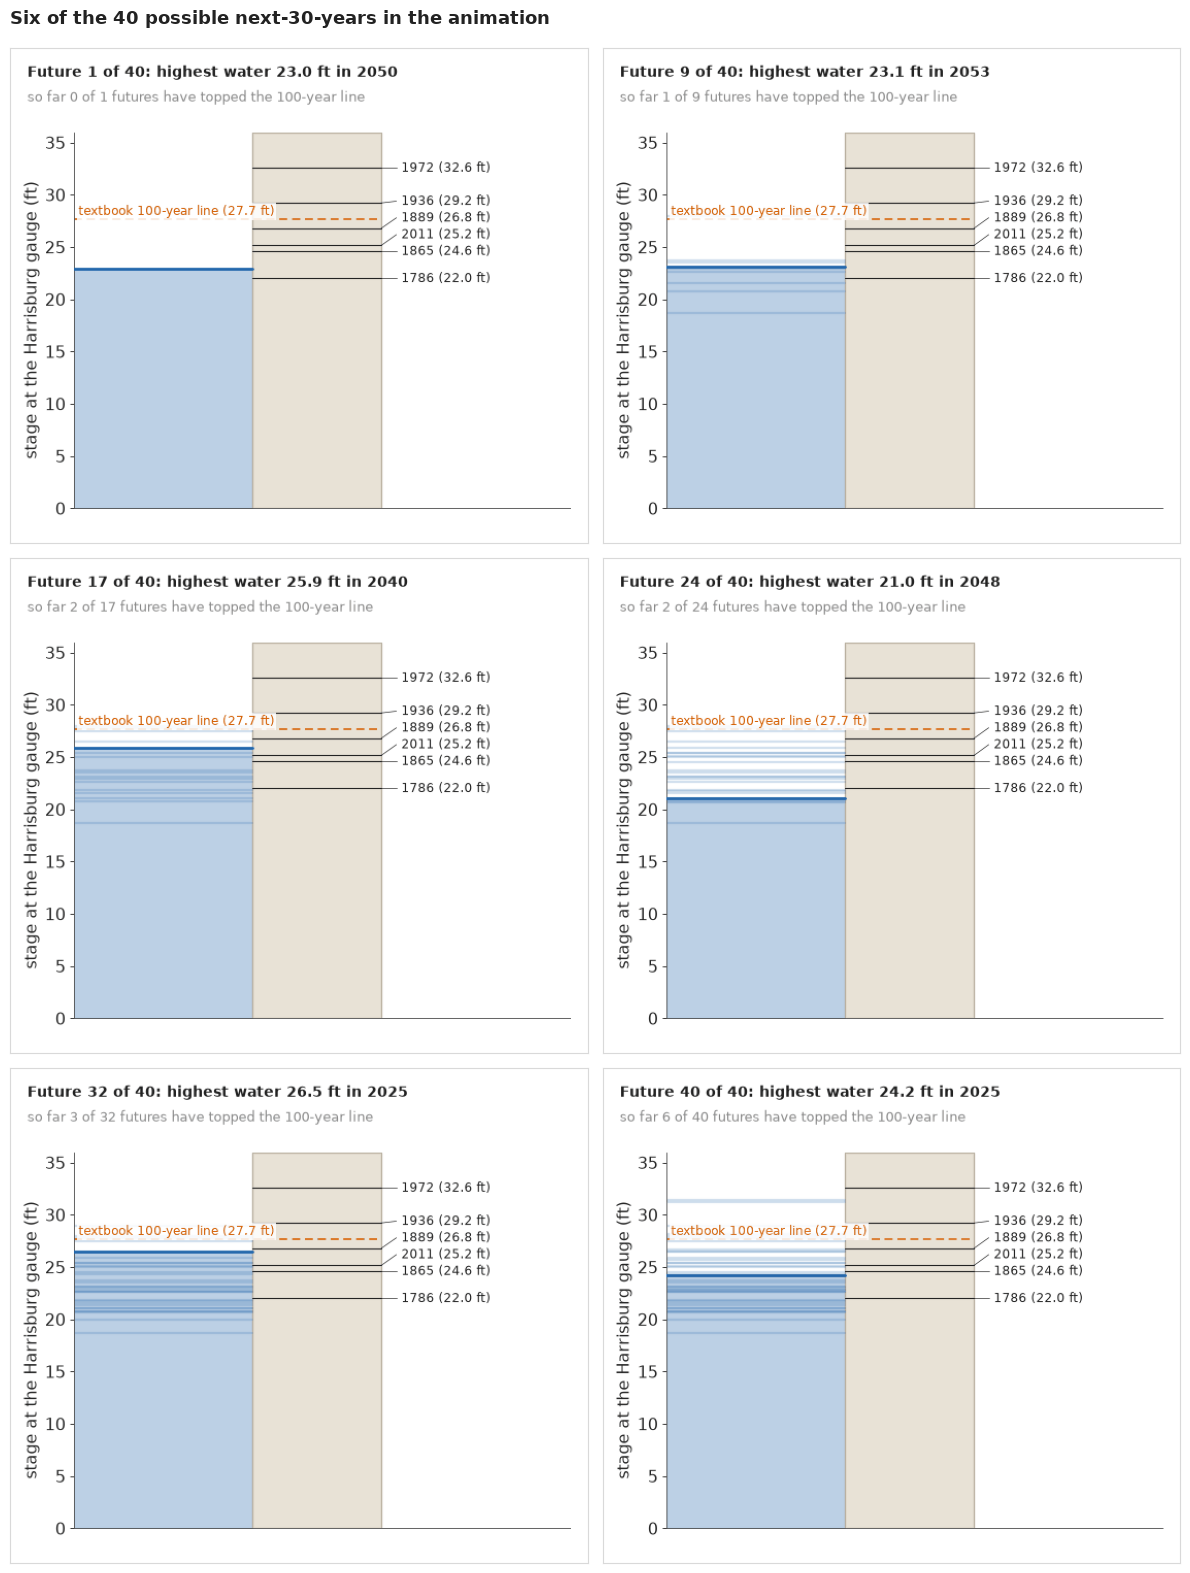

In [36]:
NB_STEM = "E113_hundred_year_flood"
GIF = f"{NB_STEM}_next30.gif"  # written next to the notebook: the site copies every {stem}*.gif
NF = 40
gr = np.random.default_rng(11)
pick = gr.choice(4000, NF, replace=False)
sims = np.array([10 ** stats.pearson3.rvs(STACK[2][i], loc=STACK[0][i], scale=STACK[1][i], size=30,
                                          random_state=gr) for i in pick])
HMAX, YMAX = stage(sims.max(axis=1)), 2025 + sims.argmax(axis=1)
MARKS = [(int(r.water_year) - (r.water_year == 1787), float(r.gage_ht_ft))
         for _, r in HB_HIST.iterrows() if r.water_year in (1787, 1865, 1889)]
MARKS += [(wy, float(HB_SYS.loc[HB_SYS.water_year == wy, "gage_ht_ft"].iloc[0]))
          for wy in (1936, 1972, 2011)]
lab_y, prev = {}, -9.0
for yr_, h_ in sorted(MARKS, key=lambda t: t[1]):  # keep labels at least 1.1 ft apart
    lab_y[yr_] = max(h_, prev + 1.6)
    prev = lab_y[yr_]
fig_g = plt.figure(figsize=(7, 6), dpi=80, layout="none")
ax_g = fig_g.add_axes([0.11, 0.07, 0.86, 0.76])


def pier_frame(k):
    ax_g.clear()
    ax_g.add_patch(Rectangle((0.36, 0), 0.26, 36, fc="#e8e2d6", ec="#b9b0a0", lw=1.2, zorder=1))
    for yr_, h_ in MARKS:
        ax_g.plot([0.36, 0.62], [h_, h_], color=INK, lw=1.0, zorder=3)
        ax_g.plot([0.62, 0.65], [h_, lab_y[yr_]], color=INK, lw=0.6, zorder=3)
        ax_g.text(0.66, lab_y[yr_], f"{yr_} ({h_:.1f} ft)", va="center", fontsize=10.5, color=INK)
    ax_g.plot([0.0, 0.62], [H100, H100], color=LO, lw=1.4, ls=(0, (5, 3)), zorder=2)
    ax_g.text(0.01, H100 + 0.4, f"textbook 100-year line ({H100:.1f} ft)", color=LO, fontsize=10.5,
              zorder=6, bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
    for j in range(k):
        ax_g.plot([0.0, 0.36], [min(HMAX[j], 35.5)] * 2, color=HI, alpha=0.2, lw=2, zorder=1)
    ax_g.fill_between([0, 0.36], 0, min(HMAX[k], 35.5), color=HI, alpha=0.3, zorder=0)
    ax_g.plot([0.0, 0.36], [min(HMAX[k], 35.5)] * 2, color=HI, lw=2.5, zorder=4)
    ax_g.set_xlim(0, 1)
    ax_g.set_ylim(0, 36)
    ax_g.set_xticks([])
    ax_g.set_ylabel("stage at the Harrisburg gauge (ft)")
    for s in ("top", "right"):
        ax_g.spines[s].set_visible(False)
    n_up = int((HMAX[: k + 1] > H100).sum())
    fig_g.texts.clear()
    fig_g.text(0.03, 0.965, f"Future {k + 1} of {NF}: highest water {HMAX[k]:.1f} ft in "
               f"{YMAX[k]}", fontsize=12.5, color=INK, va="top", weight="bold")
    fig_g.text(0.03, 0.915, f"so far {n_up} of {k + 1} futures have topped the 100-year line",
               fontsize=11.5, color=MUTED, va="top")


t0 = time.time()
frames = pub.save_gif(fig_g, pier_frame, NF, GIF, ms=600)
plt.close(fig_g)
TIMES["GIF"] = time.time() - t0
print(f"{int((HMAX > H100).sum())} of {NF} futures top the line; highest water {HMAX.min():.1f}-"
      f"{HMAX.max():.1f} ft, middle 80% {np.quantile(HMAX, 0.1):.1f}-"
      f"{np.quantile(HMAX, 0.9):.1f} ft; at the headline chance, {NF} futures would put "
      f"{stats.binom.ppf(0.055, NF, P_HEAD):.0f} to {stats.binom.ppf(0.945, NF, P_HEAD):.0f} "
      f"above the line (89%)")
pub.gif_contact_sheet(frames, title=f"Six of the {NF} possible next-30-years in the animation");

The animation is saved as
[E113_hundred_year_flood_next30.gif](E113_hundred_year_flood_next30.gif), small enough for a
message or a slide; the six frames above are its static companion for print, with the alt text
below for screen readers.

![Animated flood marks on a bridge pier at Harrisburg: lines for 1786, 1865, 1889, 1936, 1972 and
2011, and a dashed 100-year line at 27.7 ft; in each frame the water rises to the highest level of
one possible next 30 years, in most frames between about 21 and 28 ft, and in a few of the 40
frames it tops the line](E113_hundred_year_flood_next30.gif)

Watching 40 futures, a reader sees most peak between about 21 and 28 ft, around the old marks,
and a few climb past the dashed line: a frequency, not a phrase. The count can sit anywhere in
the binomial range printed above, a fair lesson in how lumpy rare events are. One risk: the 1936
and 1972 marks tower over the typical water, and a reader may conclude that such floods "cannot
happen any more", which the first bar of the headline corrects.

### What the public version gains, and what it costs

The return-level plot answers the engineer's question, how big the flood of each return period
is; the chance-of bars answer the homeowner's, what the odds are over the years they will be
there. What the bars give up is the shape of the tail: nothing in them shows Agnes far above the
fitted curve. And they invite a precision the events do not have: the 2 ft bar rests on a rating
line fitted to 22 floods, the textbook flow is our own calculation, and none of this replaces a
flood map.

In [37]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'compile one gauge': 11, 'gauged, vague skew': 1, 'gauged, regional skew': 1, '+ floods of 1786-1889': 1, '+ history as ±25% intervals': 0, 'compile twelve gauges': 12, 'twelve gauges, stationary': 14, 'decline after 1950': 17, 'step at 1950': 17, 'decline + spread trend': 23, 'compile centred': 11, 'centred location, decline after 1950': 36, 'decline, regulated peaks dropped': 37, 'compile eleven gauges': 12, 'eleven gauges (no Harrisburg), stationary': 11, 'Harrisburg alone, stationary': 0, 'Harrisburg alone, decline after 1950': 0, 'Harrisburg alone, step at 1950': 1, 'GIF': 3, 'total': 224}


## Summary

- **A library gradient was wrong where the data live.** PyTensor's shape derivative of the
  incomplete gamma function is wrong by orders of magnitude at shape 44 (skew 0.3) and NaN from
  about 400; a 48-node quadrature of the density gives the tail within $10^{-6}$ of SciPy.
- **A support must say "impossible".** A clamp that kept the log density finite scored a mean of
  $10^{33}$ cfs about 150,000 log units above a sensible fit; a `switch` to $-\infty$ fixed it.
- **History is data.** Six floods from 1786-1889 and 98 years with nothing comparable moved
  Harrisburg's 100-year flow from about 720,000 to 660,000 cfs and narrowed its 89% range by a
  third. A latent perception threshold, with chance records summed out exactly, put about half its
  weight on 482,000 cfs: Harrisburg's old record is complete only for the biggest floods. At
  Hancock and on the Schuylkill the 17C default holds; at Wilkes-Barre, as at Harrisburg, the old
  record is complete only for the larger floods. One "nothing above the mark" claim (Marietta's)
  fails a check against its neighbour and was dropped; Hancock's is in tension with one.
- **Twelve gauges share one skew**, about 0.26 ± 0.06 (USGS regional 0.32, for a region that
  leaves out the Potomac), with area exponent 0.80; Harrisburg's skew shrank from 0.44 to 0.29
  and its 100-year flow to about 640,000.
- **A centred location failed against a moving wall, at some seeds only.** At two of five seeds
  one or two chains stuck at the support wall (r_hat about 3, ESS 5); non-centred was clean at all.
- **The river probably got calmer, and we do not know why.** Yearly peaks are about 11% lower
  than before mid-century (regional trend $-0.066 \pm 0.020$ log10 per century), with no change in
  spread; at Harrisburg most of that drop is against 1891-1931, since against 1932-1949 its median
  is only 1% lower. The twelve gauges' yearly peaks correlate at about 0.56, worth fewer than two
  independent gauges, so the regional certainty is overstated: Harrisburg alone makes some drop
  about 95% likely under a steady decline and about 85% under a step. Leaving out whole
  water years, LOO can no longer tell the decline from no change (about 4 ± 9), and stacking
  gives no change about a third of the weight. Dropping the regulated peaks leaves the decline in
  place but cannot rule out dams.
- **Over 2025-2054 at Harrisburg**, held at today's level and stacked by year: about 11%
  (3-22%) for the textbook 100-year flow, *unlikely*, against 26% for "1-in-100 a year";
  about 8% if the decline is real, about 14% if the river has not changed, about 16% back at its
  pre-1950 level; about 4% for water 2 ft above the line, about 30% for a Lee and about 1%
  for an Agnes. Harrisburg fitted alone gives 8-15% across its three shapes. Low
  confidence: it rests on a drop whose cause and permanence are unknown.
- **For the public**: chance-of bars with gradient whiskers, printed ranges and grey reference
  bars; a strip of what would change our mind; a flood-marks HOP GIF with a still companion; and
  the return-level plot, which doubles as the posterior predictive check, as the contrast.

## Try it yourself

1. **A shared year effect.** Give every water year an effect common to all gauges, the proper fix
   for the correlation of part F, and see how far the regional decline's sd grows and whether
   the 30-year chance moves. (Each gauge's yearly distribution becomes a mixture over the effect.)
2. **A step at the dams.** Most of the regulated gauges change in 1966-1980, when the big
   flood-control reservoirs filled. Give each gauge a step at its own first regulated year (or at
   1972 for the rest) and compare it by stacking with the step at 1950. Does the timing of the
   drop point to the dams?
3. **A different region.** The Schuylkill and the three Potomac gauges drain other basins. Fit
   them as a second region with its own $\gamma_R$ and $\delta_R$, or add a region level to the
   hierarchy, and see whether the Susquehanna's decline and skew survive.